### **Distributed Lag Non-Linear Model**

In [452]:
# Import necessary libraries

# Basics
import itertools
import warnings
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DLNM helpers 
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from dlnm import plot_crosspred, cb_pen

# statsmodels for GLMGam
import statsmodels.api as sm
from statsmodels.gam.api import GLMGam
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines, GenericSmoothers
from statsmodels.tsa.stattools import acf

# PyMC + ArviZ for the final ZINB model
import pymc as pm
import arviz as az

In [453]:
def cb_construct(dataframe, col_lst, max_lag, setting_lst):
    var_degree, var_df, lag_degree, lag_df = setting_lst

    cb_list = []
    for col in col_lst:
        cb = CrossBasis(
            dataframe[col].values, lag=max_lag,
            argvar={"fun": "bs", "degree": var_degree, "df": var_df},
            arglag={"fun": "bs", "degree": lag_degree, "df": lag_df}
        )
        cb_list.append(cb)

    X_exposure = np.concatenate([np.asarray(cb) for cb in cb_list], axis=1)
    n_basis_per_exp = X_exposure.shape[1] // len(col_lst)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(n_basis_per_exp)]

    base = dataframe.reset_index(drop=True).iloc[max_lag:].copy()
    basis_df = pd.DataFrame(X_exposure[max_lag:], columns=exp_name_list, index=base.index)
    model_data = pd.concat([base, basis_df], axis=1)
    
    return model_data, exp_name_list, cb_list

In [454]:
def smoother_construct(dataframe, bs_dict, ccs_dict):
    bs_list = []
    for i, name in enumerate(bs_dict["name"]):
        bs = UnivariateBSplines(dataframe[name].values, df=bs_dict["df"][i], degree=bs_dict["degree"][i], variable_name=name, include_intercept=False)
        bs_list.append(bs)

    ccs_list = []
    for i, name in enumerate(ccs_dict["name"]):
        ccs = UnivariateCubicCyclicSplines(dataframe[name].values, df=ccs_dict["df"][i], variable_name=name, constraints="center")
        ccs_list.append(ccs)

    sm_weights = bs_list + ccs_list
    smooth_names = list(bs_dict["name"]) + list(ccs_dict["name"])
    X_smooth = dataframe[smooth_names]
    
    return GenericSmoothers(X_smooth, sm_weights)

In [455]:
def model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para):
    terms = list(exp_names) + list(linear_predictors)
    formula = f"{tar_var} ~ {' + '.join(terms)}"
    alpha = np.asarray(alpha, dtype=float)

    model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=alpha, family=sm.families.NegativeBinomial(alpha=disp_para), offset=dataframe["Log_population"].to_numpy(dtype=float))
    result = model.fit()
    
    return model, result

In [456]:
def cb_tune(dataframe, tar_var, exp_col, linear_predictors, bs_dict, ccs_dict, alpha, disp_para, max_lag, grid):
    print(f"{'='*10} Tuning CrossBasis settings {'='*10}")
    best_idx = 0
    performance = []

    for option in grid:
        model_data, exp_names, _ = cb_construct(dataframe, exp_col, max_lag, option)
        smoothers = smoother_construct(model_data, bs_dict, ccs_dict)
        try:
            _, result = model_construct(model_data, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic = np.inf
        performance.append(bic)
        print(f"BIC for {option}: {bic:.2f}" if np.isfinite(bic) else f"BIC for {option}: failed")

    for i in range(1, len(performance)):
        if performance[i] < performance[best_idx]:
            best_idx = i

    best_setting = grid[best_idx]
    print(f"Best CrossBasis setting: {best_setting} (BIC = {performance[best_idx]:.2f})")
    
    return cb_construct(dataframe, exp_col, max_lag, best_setting)

In [457]:
def smoother_tune(dataframe, tar_var, exp_names, linear_predictors, alpha, disp_para, bs_name_lst, ccs_name_lst, grid):
    print(f"\n{'='*10} Tuning smoother degrees of freedom {'='*10}")
    n_bs = len(bs_name_lst)
    best_idx = 0
    performance = []

    for option in grid:
        bs_dfs = list(option[:n_bs])
        ccs_dfs = list(option[n_bs:])

        bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": bs_dfs}
        ccs_dict = {"name": ccs_name_lst, "df": ccs_dfs}

        smoothers = smoother_construct(dataframe, bs_dict, ccs_dict)
        try:
            _, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
            edf = float(np.sum(result.edf))
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic, edf = np.inf, np.nan

        performance.append((bic, edf))
        print(f"Degrees of freedom {option}: BIC={bic:.4f} | sum(EDF)={edf:.4f}")

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_idx][0]:
            best_idx = i

    best_option = grid[best_idx]
    print(f"Best smoother setting: {best_option} (BIC={performance[best_idx][0]:.4f})")

    bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": list(best_option[:n_bs])}
    ccs_dict = {"name": ccs_name_lst, "df": list(best_option[n_bs:])}
    
    return smoother_construct(dataframe, bs_dict, ccs_dict)

In [458]:
def alpha_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para, criterion_lst=["bic", "gcv"], method="nm"):
    print(f"\n{'='*10} Tuning smoother weights (α) {'='*10}")
    start_alpha = np.asarray(start_alpha, dtype=float)
    model, _ = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para)

    alpha_out_lst = []
    for criterion in criterion_lst:
        best_alpha = model.select_penweight(criterion=criterion, method=method,
                                            start_params=start_alpha)
        if isinstance(best_alpha, (list, tuple)):
            candidate = best_alpha[0]
            alpha_out = np.asarray(candidate if np.ndim(candidate) > 0 else best_alpha, dtype=float)
        else:
            alpha_out = np.asarray(best_alpha, dtype=float).ravel()
        alpha_out_lst.append(alpha_out)
        print(f"Best alpha found with {criterion}: {alpha_out}")

    # ensure derivative bases exist (original safeguard)
    for s in smoothers.smoothers:
        if getattr(s, "der_basis", None) is None:
            s.der_basis = np.zeros_like(s.basis)
        if getattr(s, "der2_basis", None) is None:
            s.der2_basis = np.zeros_like(s.basis)

    try:
        best_a_kfold = model.select_penweight_kfold()
        alpha_out_lst.append(best_a_kfold[0])
        print(f"Best alpha found with Kfold: {best_a_kfold[0]}")
    except Exception as e:
        print(f"Kfold alpha selection failed: {e}")
        alpha_out_lst.append(alpha_out_lst[0])

    # comparison table
    results = {}
    for name, a in zip(criterion_lst+["KFold"], alpha_out_lst):
        try:
            _, res = model_construct(dataframe, tar_var, exp_names, linear_predictors,
                                    smoothers, a, disp_para)
            results[name] = {"alpha": a, "AIC": res.aic, "BIC": res.bic, "GCV": getattr(res, "gcv", np.nan), "EDF": res.edf.sum()}
        except Exception:
            results[name] = {"alpha": a, "AIC": np.nan, "BIC": np.nan, "GCV": np.nan, "EDF": np.nan}

    print("Alpha values comparison:")
    display(pd.DataFrame(results).T)
    return alpha_out_lst[-1]   # return Kfold-selected alpha

In [459]:
def disp_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_grid):
    print(f"\n{'='*10} Tuning Negative Binomial dispersion parameter {'='*10}")
    performance = []

    for disp in disp_grid:
        try:
            _, result = model_construct(
                dataframe, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp,
            )
            pearson_ratio = result.pearson_chi2 / result.df_resid
            performance.append((disp, pearson_ratio, result.bic))
            print(f"Dispersion {disp:5.1f}: Pearson ratio = {pearson_ratio:.4f} | BIC = {result.bic:.4f}")
        except Exception as e:
            print(f"Dispersion {disp} failed: {e}")

    if not performance:
        raise RuntimeError("All dispersion values failed.")

    best = min(performance, key=lambda x: abs(x[1] - 1.0))
    print(f"\nBest dispersion parameter: {best[0]} (Pearson ratio = {best[1]:.4f})")
    return best[0]

In [460]:
def extract_smoother_bases(smoothers):

    bases = []
    for s in smoothers.smoothers:
        name = getattr(s, "variable_name", "smooth")
        # statsmodels Univariate* objects store the evaluated basis in .basis
        B = np.asarray(s.basis)
        bases.append((name, B))
    return bases


def build_full_design_matrix(model_data, exp_name_list, linear_predictors_list, smoothers):

    parts = []
    col_names = []

    # 1. Cross-basis columns (already present in model_data)
    X_cb = model_data[exp_name_list].values
    parts.append(X_cb)
    col_names.extend(exp_name_list)

    # 2. Linear predictors
    X_lin = model_data[linear_predictors_list].values
    parts.append(X_lin)
    col_names.extend(linear_predictors_list)

    # 3. Smoother bases
    for name, B in extract_smoother_bases(smoothers):
        parts.append(B)
        col_names.extend([f"{name}_s{i}" for i in range(B.shape[1])])

    X = np.column_stack(parts)
    # drop any constant / all-zero columns that can appear after lag truncation
    keep = np.std(X, axis=0) > 1e-12
    X = X[:, keep]
    col_names = [c for c, k in zip(col_names, keep) if k]

    return X, col_names

In [461]:
def model_construct_zinb(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, prior_sigma=2.0, psi_prior="constant", draws=1000, tune=1000, target_accept=0.95, cores=2, chains=2, random_seed=42):

    y = model_data[tar_var].values.astype("float64")
    X, colnames = build_full_design_matrix(model_data, exp_name_list, linear_predictors_list, smoothers)
    n_obs, n_coef = X.shape
    print(f"Design matrix shape for ZINB: {X.shape}")

    coords = {"coef": colnames, "obs": np.arange(n_obs)}

    with pm.Model(coords=coords) as model:
        # data containers (optional but useful for posterior predictive later)
        X_data = pm.Data("X", X, dims=("obs", "coef"))
        y_data = pm.Data("y", y, dims="obs")

        # coefficients for the count mean (log link)
        beta = pm.Normal("beta", mu=0.0, sigma=prior_sigma, dims="coef")

        eta = pm.math.dot(X_data, beta)
        mu = pm.math.exp(eta)

        # zero-inflation probability
        if psi_prior == "constant":
            psi = pm.Beta("psi", alpha=2.0, beta=2.0)
        else:  # logistic
            gamma = pm.Normal("gamma", mu=0.0, sigma=1.0, dims="coef")
            logit_psi = pm.math.dot(X_data, gamma)
            psi = pm.Deterministic("psi", pm.math.invlogit(logit_psi), dims="obs")

        # dispersion (shape) of the NB component
        alpha = pm.HalfNormal("alpha", sigma=5.0)

        # likelihood
        pm.ZeroInflatedNegativeBinomial("y_obs", psi=psi, mu=mu, alpha=alpha, observed=y_data, dims="obs")

        print("Sampling ZINB model …")
        idata = pm.sample(draws=draws, tune=tune, chains=chains, target_accept=target_accept, cores=cores, random_seed=random_seed, return_inferencedata=True, progressbar=True)

    return model, idata, X, colnames

In [462]:
def build_separated_design_matrices(model_data, exp_name_list, linear_predictors_list, smoothers, psi_predictors):
    # ----- 1. Full matrix for the mean (same as before) -----
    X_mu, colnames_mu = build_full_design_matrix(
        model_data, exp_name_list, linear_predictors_list, smoothers
    )
    X_mu = np.column_stack([np.ones(X_mu.shape[0]), X_mu])
    colnames_mu = ["intercept_mu"] + list(colnames_mu)

    # ----- 2. Simple matrix for psi -----
    # psi_predictors is a list of column names that exist in model_data
    # Example: ["school_flag", "pandemic_flag"] 
    # You can also add a few seasonal basis columns if you want.

    X_psi = model_data[psi_predictors].values.astype(float)

    # Optional but recommended: add an intercept to psi
    X_psi = np.column_stack([np.ones(len(X_psi)), X_psi])
    colnames_psi = ["intercept_psi"] + list(psi_predictors)

    return X_mu, colnames_mu, X_psi, colnames_psi

In [463]:
def model_construct_zinb_separated(model_data, tar_var, X_mu, colnames_mu, X_psi, colnames_psi, log_pop, prior_sigma=2.5, draws=1000, tune=1000, target_accept=0.95, cores=2, chains=2, random_seed=42):
    y = model_data[tar_var].values.astype("float64")
    n_obs = len(y)

    coords = {
        "coef_mu": list(colnames_mu),
        "coef_psi": list(colnames_psi),
        "obs": np.arange(n_obs)
    }

    with pm.Model(coords=coords) as model:
        X_mu_data   = pm.Data("X_mu", X_mu, dims=("obs", "coef_mu"))
        X_psi_data  = pm.Data("X_psi", X_psi, dims=("obs", "coef_psi"))
        log_pop_data = pm.Data("log_pop", log_pop, dims="obs")
        y_data      = pm.Data("y", y, dims="obs")

        # ----- Count mean -----
        beta = pm.Normal("beta", mu=0.0, sigma=prior_sigma, dims="coef_mu")
        eta_mu = pm.math.dot(X_mu_data, beta) + log_pop_data   # offset
        mu = pm.math.exp(eta_mu)

        # ----- Zero-inflation -----
        gamma = pm.Normal("gamma", mu=0.0, sigma=1.5, dims="coef_psi")
        logit_psi = pm.math.dot(X_psi_data, gamma)
        psi = pm.Deterministic("psi", pm.math.invlogit(logit_psi), dims="obs")

        # Dispersion
        alpha = pm.HalfNormal("alpha", sigma=5.0)

        # Likelihood
        pm.ZeroInflatedNegativeBinomial(
            "y_obs", psi=psi, mu=mu, alpha=alpha,
            observed=y_data, dims="obs"
        )

        print("Sampling separated ZINB model …")
        idata = pm.sample(
            draws=draws, tune=tune, chains=chains,
            target_accept=target_accept, cores=cores,
            random_seed=random_seed,
            return_inferencedata=True, progressbar=True
        )
        idata = pm.compute_log_likelihood(idata, model=model)

    return model, idata, X_mu, colnames_mu

In [464]:
def extract_cb_coef_from_idata(idata, colnames, exp_name, return_vcov=True, coef_dim="coef_mu"):
    basis_names = [n for n in colnames if n.startswith(f"{exp_name}_basis_")]
    if not basis_names:
        raise ValueError(f"No basis coefficients found for exposure '{exp_name}'.")

    # posterior samples of beta: (chain, draw, coef)
    beta_samples = idata.posterior["beta"].sel({coef_dim: basis_names}).values    # flatten chains
    beta_flat = beta_samples.reshape(-1, len(basis_names))

    coef_mean = beta_flat.mean(axis=0)
    if return_vcov:
        vcov = np.cov(beta_flat, rowvar=False)
        return coef_mean, vcov, basis_names
    return coef_mean, None, basis_names

In [465]:
def pred_cal(result_or_idata, cb_list, dataframe, exp_col_list, exp_idx=0, colnames=None):

    exp = exp_col_list[exp_idx]

    if hasattr(result_or_idata, "params"):  # statsmodels path 
        param_names = list(result_or_idata.params.index)
        basis_names = [n for n in param_names if n.startswith(f"{exp}_basis_")]
        if not basis_names:
            raise ValueError(f"No basis coefficients found for exposure '{exp}'.")
        cb_coef = result_or_idata.params[basis_names].values
        cb_vcov = result_or_idata.cov_params().loc[basis_names, basis_names].values
    else:  # PyMC InferenceData path
        if colnames is None:
            raise ValueError("colnames must be provided when using a PyMC idata.")
        cb_coef, cb_vcov, _ = extract_cb_coef_from_idata(result_or_idata, colnames, exp, return_vcov=True, coef_dim="coef_mu")

    at = np.linspace(dataframe[exp].min(), dataframe[exp].max(), 100)
    cen = float(dataframe[exp].median())

    pred = crosspred(basis=cb_list[exp_idx], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)
    print(f"{exp} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")
    return pred, exp, cen

In [466]:
def graph_3Dplot(pred, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping 3-D plot.")
        return
    fig = plot_crosspred(pred, ptype="3d")
    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel(exp_name, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Relative Risk (RR)", labelpad=10)
    try:
        collections = ax.collections[0]
        vmin, vmax = collections.get_array().min(), collections.get_array().max()
        collections.set_clim(vmin, vmax)
        cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)
    except Exception:
        pass
    plt.tight_layout()
    plt.show()

def graph_exp_plot(pred, exp_name, cen):
    if plot_crosspred is None:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred.at, pred.allRRfit, color="C0", lw=2)
        if hasattr(pred, "allRRlow") and hasattr(pred, "allRRhigh"):
            ax.fill_between(pred.at, pred.allRRlow, pred.allRRhigh, alpha=0.25, color="C0")
        ax.axhline(1, color="gray", ls="--", alpha=0.7)
        ax.axvline(cen, color="black", ls=":", lw=1.2, label=f"Centering {exp_name} ({cen:.4f})")
        ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=12)
        ax.set_xlabel(exp_name, fontsize=12)
        ax.set_ylabel("Relative Risk (RR)", fontsize=12)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        return

    fig = plot_crosspred(pred, ptype="overall")
    ax = fig.gca()
    ax.axvline(x=cen, color="black", linestyle=":", linewidth=1.2,
               label=f"Centering {exp_name} ({cen:.4f})")
    ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=15)
    ax.set_xlabel(exp_name, fontsize=12)
    ax.legend(loc="best", frameon=True)
    plt.show()


def graph_lag_plot(pred, tar_val, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping lag-slice plot.")
        return
    fig = plot_crosspred(pred, ptype="slices", var=tar_val)
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {tar_val:.4f}",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()


def graph_plot(pred, exp_name, cen, lag_slice_val=None):
    graph_3Dplot(pred, exp_name)
    graph_exp_plot(pred, exp_name, cen)
    if lag_slice_val is None:
        lag_slice_val = cen
    graph_lag_plot(pred, lag_slice_val, exp_name)

In [467]:
def model_metric(result):
    print(f"AIC: {result.aic}")
    print(f"BIC: {result.bic}")
    print(f"Deviance: {result.deviance}")
    print(f"Pearson Chi2: {result.pearson_chi2}")
    print(f"Scale/Dispersion: {result.scale}")
    print(f"Effective degree of freedom: \n{result.edf}")
    print(f"Total EDF: {result.edf.sum()}")

In [468]:
def model_metric_zinb(idata):
    print("===== PyMC ZINB posterior summary (selected parameters) =====")
    display(az.summary(idata, var_names=["psi", "beta", "gamma", "alpha"], round_to=3))


In [469]:
def residual_diagnostics(result):
    residuals = result.resid_deviance

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    # 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
    axes[0].scatter(result.fittedvalues, residuals, alpha=0.3)
    axes[0].axhline(0, color='red', linestyle='--')
    axes[0].set_xlabel("Fitted Values")
    axes[0].set_ylabel("Deviance Residuals")
    axes[0].set_title("Residuals vs Fitted")

    # 2. Autocorrelation Check (ACF) 
    # Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
    sm.graphics.tsa.plot_acf(residuals, lags=10, ax=axes[1])
    axes[1].set_xlabel("Lag (Week)")
    axes[1].set_title("Autocorrelation of Residuals (ACF)")

    plt.tight_layout()
    plt.show()

In [470]:
def residual_diagnostics_zinb(idata, model_data, tar_var, X_mu, colnames_mu, log_pop=None, max_acf_lags=10, report=None):
    y = model_data[tar_var].values.astype(float)

    '''
    # posterior means
    beta_mean = idata.posterior["beta"].mean(dim=("chain", "draw")).values
    # align with colnames order used when sampling
    if "coef" in idata.posterior["beta"].coords:
        beta_mean = idata.posterior["beta"].mean(dim=("chain", "draw")).sel(coef=colnames).values

    eta = X_mu @ beta_mean
    if log_pop is not None:
        eta = eta + log_pop
    mu = np.exp(eta)

    # psi (scalar or vector)
    if "psi" in idata.posterior:
        psi_da = idata.posterior["psi"]
        if "obs" in psi_da.dims:
            psi = psi_da.mean(dim=("chain", "draw")).values
        else:
            psi = float(psi_da.mean())
    else:
        psi = 1.0

    alpha = float(idata.posterior["alpha"].mean())

    # Mean and variance of ZINB
    mean_hat = psi * mu
    var_hat = psi * mu * (1.0 + mu / alpha) + psi * (1.0 - psi) * mu**2
    var_hat = np.maximum(var_hat, 1e-8)  

    # Pearson residuals
    resid = (y - mean_hat) / np.sqrt(var_hat)
    '''
    if report is None:
        raise ValueError(
            "Pass the output of zinb_numerical_report() as report."
        )

    mean_hat = np.asarray(report["fitted_mean"], dtype=float)
    resid = np.asarray(report["pearson_residuals"], dtype=float)

    if mean_hat.shape != y.shape or resid.shape != y.shape:
        raise ValueError(
            "Report and model_data must refer to the same observations."
        )

    psi = (
        idata.posterior["psi"].mean().item()
        if "psi" in idata.posterior
        else 1.0
    )

    # ---------- Plots ----------
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # 1. Residuals vs Fitted
    axes[0].scatter(mean_hat, resid, alpha=0.35, s=12, edgecolors="none")
    axes[0].axhline(0, color="red", ls="--", lw=1)
    axes[0].set_xlabel("Fitted values (E[Y])")
    axes[0].set_ylabel("Pearson residuals")
    axes[0].set_title("Residuals vs Fitted (ZINB)")

    # 2. ACF of residuals
    sm.graphics.tsa.plot_acf(resid, lags=max_acf_lags, ax=axes[1], title="ACF of Pearson residuals")
    axes[1].set_xlabel("Lag")

    # 3. Histogram of residuals
    axes[2].hist(resid, bins=40, density=True, alpha=0.7, edgecolor="white")
    axes[2].axvline(0, color="red", ls="--", lw=1)
    axes[2].set_xlabel("Pearson residual")
    axes[2].set_ylabel("Density")
    axes[2].set_title("Residual distribution")

    plt.tight_layout()
    plt.show()

    # quick numeric summary
    print(f"Pearson residual mean   : {resid.mean():.4f}")
    print(f"Pearson residual std    : {resid.std():.4f}")
    print(f"Proportion of zeros in y: {(y == 0).mean():.3f}")
    print(f"Posterior mean psi      : {np.mean(psi):.3f}")

    return resid, mean_hat


In [471]:
def trace_plot_zinb(idata):
    pc = az.plot_trace_dist(idata, var_names=["psi", "gamma", "alpha"], compact=True)
    pc.add_legend("chain", title="Sampling chains")
    plt.tight_layout()
    plt.show()


In [472]:
def posterior_group_names(idata):
    """Return normalized group names for InferenceData or DataTree."""
    groups = getattr(idata, "groups", None)

    if groups is None:
        raise TypeError(
            f"{type(idata).__name__} does not expose a groups interface."
        )

    groups = groups() if callable(groups) else groups

    return {
        str(name).strip("/")
        for name in groups
        if str(name).strip("/")
    }

In [473]:
def zinb_numerical_report(
    idata,
    max_acf_lag=10,
    predictive_draws=1000,
    random_seed=42,
):

    required = ["X_mu", "log_pop", "y"]
    missing = [name for name in required
               if name not in idata.constant_data]
    if missing:
        raise ValueError(f"Missing constant_data variables: {missing}")

    y = np.asarray(idata.constant_data["y"], dtype=float)
    X = np.asarray(idata.constant_data["X_mu"], dtype=float)
    offset = np.asarray(idata.constant_data["log_pop"], dtype=float)

    if len(y) < 3:
        raise ValueError("At least three observations are required.")

    beta = (
        idata.posterior["beta"]
        .stack(sample=("chain", "draw"))
        .transpose("sample", "coef_mu")
        .values
    )

    alpha = (
        idata.posterior["alpha"]
        .stack(sample=("chain", "draw"))
        .transpose("sample")
        .values[:, None]
    )

    psi_da = idata.posterior["psi"].stack(
        sample=("chain", "draw")
    )
    if "obs" in psi_da.dims:
        psi = psi_da.transpose("sample", "obs").values
    else:
        psi = psi_da.transpose("sample").values[:, None]

    eta = beta @ X.T + offset[None, :]
    with np.errstate(over="raise", invalid="raise"):
        mu = np.exp(eta)
        mean_draw = psi * mu
        var_draw = (
            psi * mu
            + psi * mu**2 / alpha
            + psi * (1.0 - psi) * mu**2
        )

    if not np.isfinite(var_draw).all():
        raise ValueError(
            "Non-finite predictive variance; inspect extreme draws."
        )

    fitted_mean = mean_draw.mean(axis=0)
    conditional_var = var_draw.mean(axis=0)
    predictive_var = conditional_var + mean_draw.var(axis=0)

    pearson = (
        (y - fitted_mean)
        / np.sqrt(np.maximum(conditional_var, 1e-12))
    )
    predictive_resid = (
        (y - fitted_mean)
        / np.sqrt(np.maximum(predictive_var, 1e-12))
    )

    log_nb_p0 = -alpha * np.log1p(mu / alpha)
    zero_probability = (
        (1.0 - psi) + psi * np.exp(log_nb_p0)
    ).mean(axis=0)

    rng = np.random.default_rng(random_seed)
    n_sim = min(int(predictive_draws), len(beta))
    if n_sim < 2:
        raise ValueError("predictive_draws must be at least 2.")

    chosen = rng.choice(len(beta), size=n_sim, replace=False)
    a = alpha[chosen]
    m = mu[chosen]
    p = a / (a + m)

    if np.any(p <= 0) or np.any(p > 1):
        raise ValueError("Invalid NB probability; inspect posterior.")

    y_rep = rng.negative_binomial(a, p)
    y_rep *= rng.random(y_rep.shape) < psi[chosen]

    q10, q90 = np.quantile(y_rep, [0.10, 0.90], axis=0)
    q025, q975 = np.quantile(y_rep, [0.025, 0.975], axis=0)
    fitted_median = np.median(y_rep, axis=0)

    metrics = pd.Series({
        "n_observations": len(y),
        "MAE_predictive_median": np.mean(
            np.abs(y - fitted_median)
        ),
        "RMSE_predictive_mean": np.sqrt(
            np.mean((y - fitted_mean)**2)
        ),
        "mean_prediction_minus_observed": np.mean(
            fitted_mean - y
        ),
        "observed_zero_fraction": np.mean(y == 0),
        "predicted_zero_fraction": zero_probability.mean(),
        "zero_event_Brier_score": np.mean(
            ((y == 0).astype(float) - zero_probability)**2
        ),
        "coverage_80": np.mean((y >= q10) & (y <= q90)),
        "coverage_95": np.mean((y >= q025) & (y <= q975)),
        "mean_interval_width_80": np.mean(q90 - q10),
        "mean_interval_width_95": np.mean(q975 - q025),
        "Pearson_residual_mean": pearson.mean(),
        "Pearson_residual_SD": pearson.std(),
        "predictive_residual_SD": predictive_resid.std(),
    }, name="in_sample_value")

    var_names = [
        v for v in ["beta", "gamma", "alpha"]
        if v in idata.posterior
    ]
    diagnostics = az.summary(
        idata, var_names=var_names, kind="diagnostics"
    )

    lag_limit = min(int(max_acf_lag), len(y) - 1)
    if np.std(pearson) > 0:
        residual_acf = pd.Series(
            acf(pearson, nlags=lag_limit, fft=False)[1:],
            index=np.arange(1, lag_limit + 1),
            name="Pearson_residual_ACF",
        )
    else:
        residual_acf = pd.Series(dtype=float)

    divergences = None
    if (
        hasattr(idata, "sample_stats")
        and "diverging" in idata.sample_stats
    ):
        divergences = int(
            idata.sample_stats["diverging"].sum().item()
        )

    sampling = {"divergences": divergences}
    for column, label, operation in [
        ("r_hat", "max_r_hat", "max"),
        ("ess_bulk", "min_bulk_ESS", "min"),
        ("ess_tail", "min_tail_ESS", "min"),
    ]:
        if column in diagnostics:
            values = diagnostics[column]
            sampling[label] = (
                values.max() if operation == "max"
                else values.min()
            )

    loo_result = None
    if not hasattr(az, "loo"):
        loo_status = "Installed ArviZ has no top-level loo API."
    elif "log_likelihood" not in posterior_group_names(idata):
        loo_status = (
            "Missing log_likelihood: compute it with the fitted model."
        )
    else:
        loo_result = az.loo(idata, pointwise=True)
        loo_status = (
            "Computed; inspect Pareto-k diagnostics. "
            "This is not leave-future-out validation."
        )

    print("IN-SAMPLE metrics: not a forecast-performance estimate.")
    display(metrics.to_frame())
    display(pd.Series(sampling, name="value").to_frame())
    display(residual_acf.to_frame())
    print(loo_status)
    if loo_result is not None:
        print(loo_result)

    return {
        "metrics": metrics,
        "sampling": sampling,
        "parameter_diagnostics": diagnostics,
        "residual_acf": residual_acf,
        "fitted_mean": fitted_mean,
        "pearson_residuals": pearson,
        "predictive_residuals": predictive_resid,
        "zero_probability": zero_probability,
        "posterior_predictive_draws": y_rep,
        "loo": loo_result,
    }

In [474]:
def DLNM_ZINB(dataframe, max_lag, tar_var, exp_col_list, linear_predictors_list, bs_name_lst, ccs_name_lst, cb_grid, smoother_grid, disp_grid, criterion_lst=["bic", "gcv"],
              # PyMC sampling controls
              draws=1500, tune=1500, target_accept=0.9, cores=2, chains=2, psi_prior="logistic", prior_sigma=1.0):

    n_smooth = len(bs_name_lst) + len(ccs_name_lst)
    initial_alpha = np.asarray([20.0] * n_smooth, dtype=float)
    initial_disp = 1.0

    init_bs_dict = {"name": bs_name_lst, "degree": [3] * len(bs_name_lst),
                    "df": [6] * len(bs_name_lst)}
    init_ccs_dict = {"name": ccs_name_lst, "df": [4] * len(ccs_name_lst)}

    # ---------- 1. Original tuning (NB) ----------
    model_data, exp_name_list, cb_list = cb_tune(dataframe, tar_var, exp_col_list, linear_predictors_list, init_bs_dict, init_ccs_dict, initial_alpha, initial_disp, max_lag, cb_grid)

    smoothers = smoother_tune(model_data, tar_var, exp_name_list, linear_predictors_list, initial_alpha, initial_disp, bs_name_lst, ccs_name_lst, smoother_grid)
    best_alpha = alpha_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, initial_alpha, initial_disp, criterion_lst, method="nm")
    best_disp = disp_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, disp_grid)

    # ---------- 2. Original results (NB) ----------
    print(f"\n{'='*15} Classic NB GLMGam (for reference) {'='*15}")
    _, nb_result = model_construct(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, best_disp)
    print(nb_result.summary().tables[1])
    model_metric(nb_result)
    residual_diagnostics(nb_result)
    pred, exp_name, cen = pred_cal(nb_result, cb_list, model_data, exp_col_list, exp_idx=0)
    graph_plot(pred, exp_name, cen, lag_slice_val=cen)

    # ---------- 3. Final PyMC ZINB ----------
    print(f"\n{'='*15} Final PyMC Zero-Inflated Negative Binomial {'='*15}")
    # _, idata, X, colnames = model_construct_zinb(
    #    model_data, tar_var, exp_name_list, linear_predictors_list, smoothers,
    #    prior_sigma=prior_sigma,
    #    psi_prior=psi_prior,
    #    draws=draws, tune=tune, target_accept=target_accept, cores=cores, chains=chains
    #)

    # Predictors you want only in the zero-inflation part
    psi_predictors = ["school_flag", "pandemic_flag"]  

    X_mu, colnames_mu, X_psi, colnames_psi = build_separated_design_matrices(
        model_data = model_data,
        exp_name_list = exp_name_list,
        linear_predictors_list = linear_predictors_list,  
        smoothers = smoothers,
        psi_predictors = psi_predictors
    )

    # After you have built the two design matrices
    log_pop = model_data["Log_population"].values   # already log-transformed

    _, idata, X_mu, colnames_mu = model_construct_zinb_separated(
        model_data = model_data,
        tar_var = tar_var,    
        X_mu = X_mu,
        colnames_mu = colnames_mu,
        X_psi = X_psi,
        colnames_psi = colnames_psi,
        log_pop = log_pop,
        prior_sigma = prior_sigma, 
        draws=draws, tune=tune, target_accept=target_accept, cores=cores, chains=chains
    )

    model_metric_zinb(idata)    

    # ---------- 3. Prediction & plots ----------
    pred, exp_name, cen = pred_cal(idata, cb_list, model_data, exp_col_list, exp_idx=0, colnames=colnames_mu)
    graph_plot(pred, exp_name, cen, lag_slice_val=cen)

    # ---------- Trace plot ----------
    trace_plot_zinb(idata)

    # ---------- 4. Model Performance ----------   
    report = zinb_numerical_report(idata, max_acf_lag=10, predictive_draws=1000)
    display(report["parameter_diagnostics"])

    # ---------- Residual diagnostics ----------
    print("\n--- Residual diagnostics (ZINB) ---")
    resid, _ = residual_diagnostics_zinb(idata, model_data, tar_var, X_mu, colnames_mu, log_pop=log_pop, max_acf_lags=10, report=report)
    
    
    return idata, pred, model_data, cb_list, colnames_mu, nb_result, resid, report


---

In [475]:
# Import data and basic settings
df = pd.read_csv("data.csv")
df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag", "Population", "Log_population", "school_flag"]

df.drop(columns=["From"], inplace=True)
df["time"] = np.arange(1, len(df) + 1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [476]:
# Overview 
display(df.head())
df.info()
display(df.describe())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,6725.8,8.813706,1.0,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,6725.8,8.813706,1.0,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,6725.8,8.813706,1.0,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,6725.8,8.813706,1.0,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,6725.8,8.813706,1.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   temprange                       1253 non-null   float64
 3   temp                            1253 non-null   float64
 4   RH                              1253 non-null   float64
 5   SR                              1253 non-null   float64
 6   AP                              1253 non-null   float64
 7   DPT                             1253 non-null   float64
 8   WS                              1253 non-null   float64
 9   UV                              1253 non-null   float64
 10  H1                              1253 non-null   int64  
 11  H3                              1253 non-null   int64  
 12  B                               12

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag,time
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,2014.172386,26.605746,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700,69.613727,115.727055,44.593450,261.437350,8.128132,0.131684,7208.379808,8.882321,0.904230,627.000000
std,6.945058,15.077257,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406,189.083854,233.728958,131.615377,439.621172,21.983305,0.338282,264.439683,0.036944,0.294393,361.854252
min,2002.000000,1.000000,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6725.800000,8.813706,0.000000,1.000000
25%,2008.000000,14.000000,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000,0.000000,5.000000,3.000000,27.000000,0.000000,0.000000,6963.900000,8.848495,1.000000,314.000000
50%,2014.000000,27.000000,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000,4.000000,28.000000,12.500000,103.000000,0.000000,0.000000,7252.900000,8.889157,1.000000,627.000000
75%,2020.000000,40.000000,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000,47.000000,125.000000,41.000000,305.000000,0.000000,0.000000,7472.600000,8.918998,1.000000,940.000000
max,2026.000000,53.000000,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,1.000000,7536.100000,8.927460,1.000000,1253.000000


In [477]:
# Ignore warnings in the tuning stage
warnings.filterwarnings("ignore", message=".*Singular matrix.*")
warnings.filterwarnings("ignore", message=".*singular matrix.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")
warnings.filterwarnings("ignore", category=FutureWarning)

In [478]:
# Basic setting for DLNM construction
linear_predictors_list = ["pandemic_flag", "school_flag"]
bs_name_lst = ["time", "ContainmentHealthIndex_Average"]
ccs_name_lst = ["Week"]

# Regarding the offset
population = df["Population"].to_numpy(dtype=float)
logged_population = df["Log_population"].to_numpy(dtype=float)

if not np.all(np.isfinite(population)) or np.any(population <= 0):
    raise ValueError("Population must contain finite positive values.")

if not np.allclose(
    logged_population,
    np.log(population),
    rtol=1e-6,
    atol=1e-6,
):
    raise ValueError(
        "Log_population is not the natural logarithm of Population. "
        "Check the population units and how the offset was constructed."
    )

# Grids for tuning hyperparameters
cb_grid = list(itertools.product([2, 3], [3, 4], [2, 3], [3, 4]))
smoother_grid = list(itertools.product([25, 30, 35, 40, 45], [4, 5, 6, 7], [8, 10, 12, 14]))
disp_grid = [1.5, 2.0, 3.0, 5.0]

**============================== temprange (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9577.70
BIC for (2, 3, 2, 4): 9600.22
BIC for (2, 3, 3, 3): 9600.22
BIC for (2, 3, 3, 4): 9600.22
BIC for (2, 4, 2, 3): 9584.34
BIC for (2, 4, 2, 4): 9613.92
BIC for (2, 4, 3, 3): 9613.92
BIC for (2, 4, 3, 4): 9613.92
BIC for (3, 3, 2, 3): 9578.32
BIC for (3, 3, 2, 4): 9601.46
BIC for (3, 3, 3, 3): 9601.46
BIC for (3, 3, 3, 4): 9601.46
BIC for (3, 4, 2, 3): 9596.60
BIC for (3, 4, 2, 4): 9627.47
BIC for (3, 4, 3, 3): 9627.47
BIC for (3, 4, 3, 4): 9627.47
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 9577.70)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (25, 4, 8): BIC=8191.2549 | sum(EDF)=46.0255
Degrees of freedom (25, 4, 10): BIC=8195.5447 | sum(EDF)=47.5141
Degrees of freedom (25, 4, 12): BIC=8200.1898 | sum(EDF)=48.8211
Degrees of freedom (25, 4, 14): BIC=8205.5878 | sum(EDF)=49.6615
Degrees of freedom (25, 5, 8): BIC=8191.2549 | sum(EDF)=46.0255
Degrees of freedom (25, 5, 10): BIC=

,alpha,AIC,BIC,GCV,EDF
KFold,"(5.011872336272722, 25.118864315095795, 630.95...",7679.790691,7967.765679,1.096331,56.134397



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   1.5: Pearson ratio = 3.3323 | BIC = 8092.7993
Dispersion   2.0: Pearson ratio = 2.3618 | BIC = 8237.7036
Dispersion   3.0: Pearson ratio = 1.2631 | BIC = 8492.2558
Dispersion   5.0: Pearson ratio = 0.5326 | BIC = 8909.1614

Best dispersion parameter: 3.0 (Pearson ratio = 1.2631)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                           -14.3242   2.13e+06  -6.72e-06      1.000   -4.18e+06    4.18e+06
temprange_basis_0                     1.3475      1.552      0.868      0.385      -1.694       4.389
temprange_basis_1                     0.4978      3.385      0.147      0.883      -6.137       7.132
temprange_basis_2                    -1.7488      1.911     -

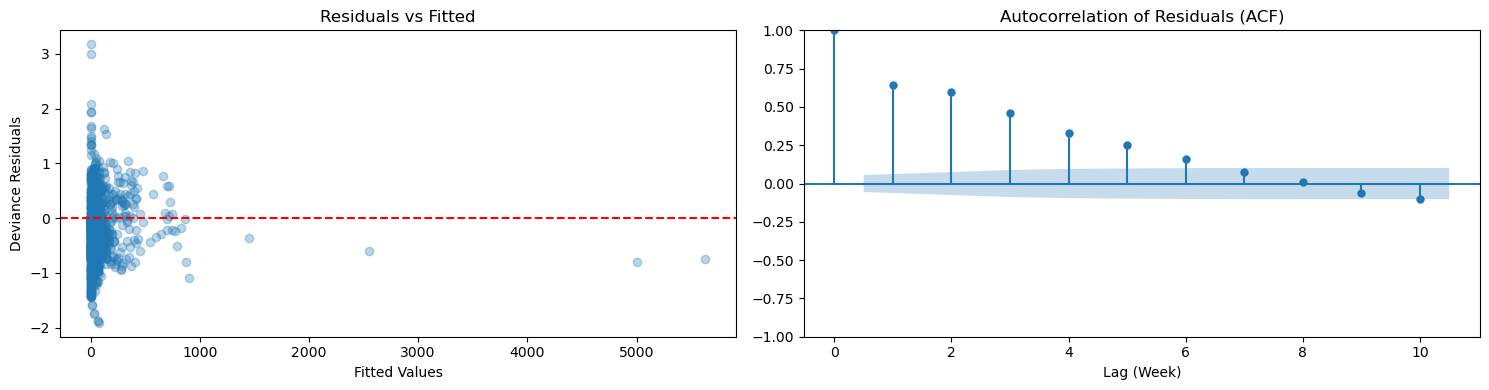

temprange RR range: 0.738 to 3.040


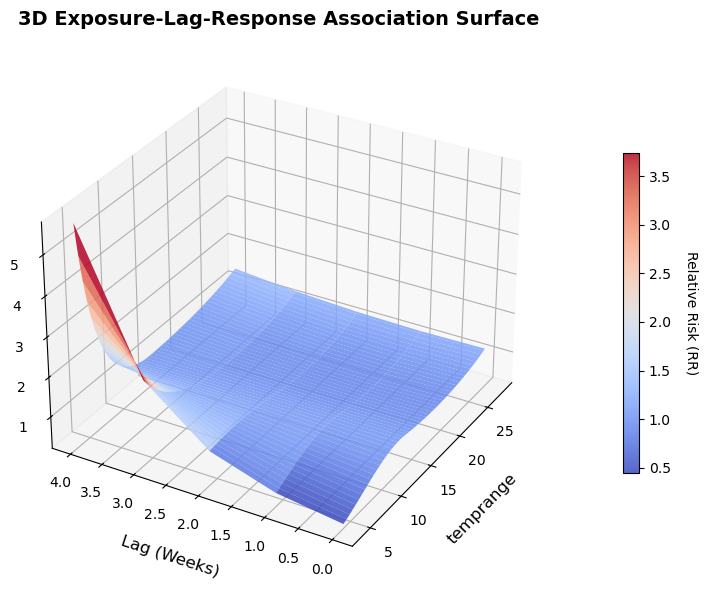

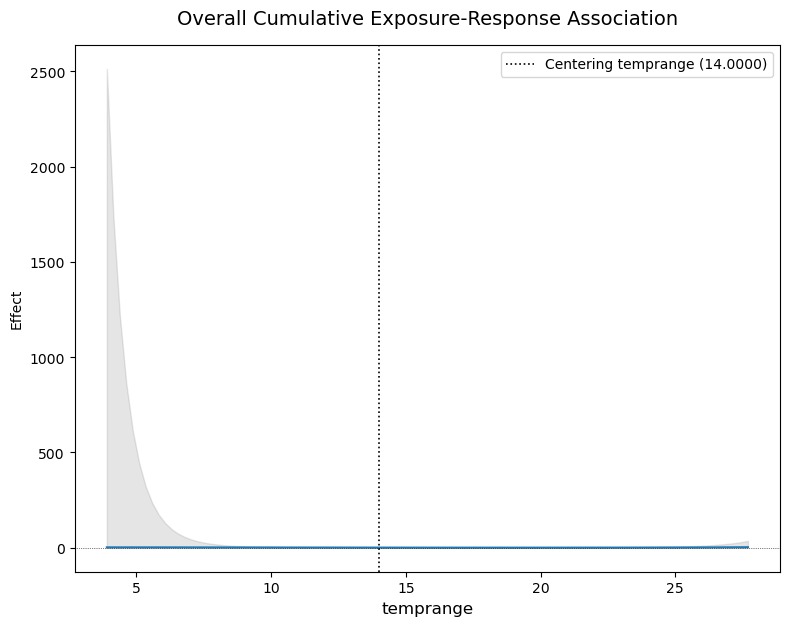

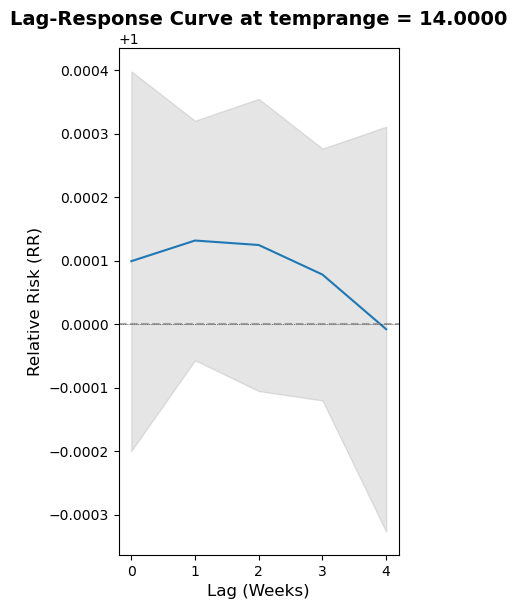


=============== Final PyMC Zero-Inflated Negative Binomial ===============
Sampling separated ZINB model …


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 222 seconds.


Output()

===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.992,0.004,0.985,0.997,6851.483,4574.394,1.000,0.000,0.000
psi[1],0.992,0.004,0.985,0.997,6851.483,4574.394,1.000,0.000,0.000
psi[2],0.992,0.004,0.985,0.997,6851.483,4574.394,1.000,0.000,0.000
psi[3],0.992,0.004,0.985,0.997,6851.483,4574.394,1.000,0.000,0.000
psi[4],0.992,0.004,0.985,0.997,6851.483,4574.394,1.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...
beta[Week_s10],-1.360,0.157,-1.612,-1.110,7569.098,4875.990,1.001,0.002,0.002
gamma[intercept_psi],3.857,0.621,2.917,4.903,6514.659,3860.774,1.002,0.008,0.009
gamma[school_flag],1.130,0.644,0.085,2.150,7307.138,4447.897,1.001,0.008,0.009
gamma[pandemic_flag],-4.767,0.610,-5.747,-3.804,7236.189,4374.877,1.000,0.007,0.010


temprange RR range: 0.677 to 90.061


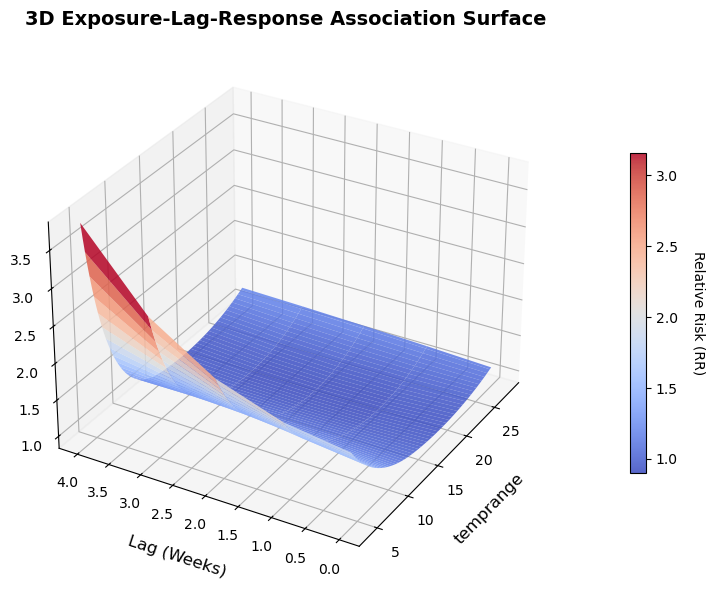

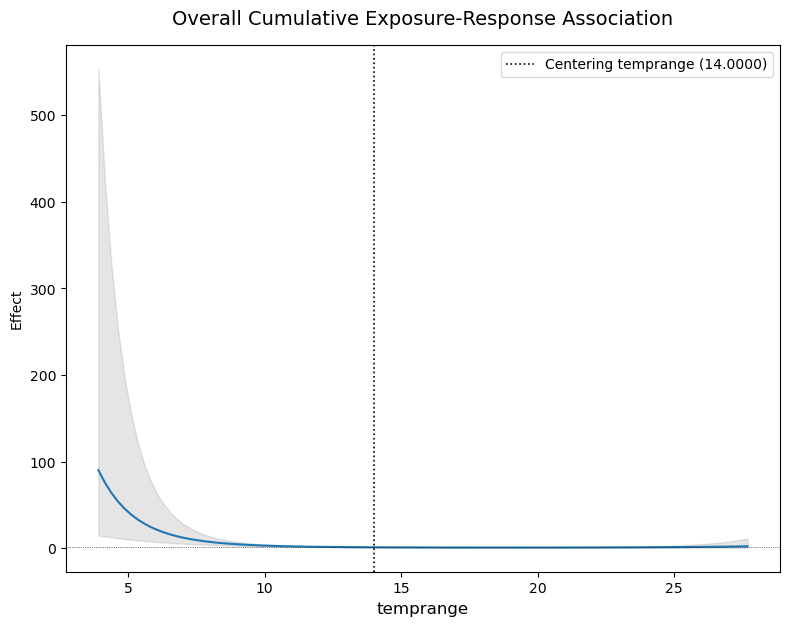

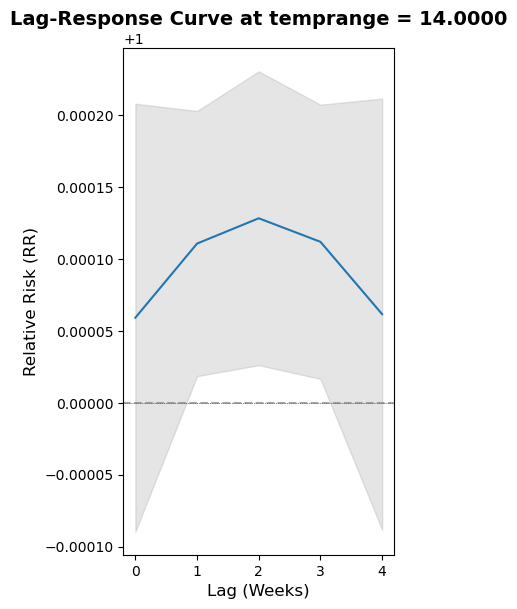

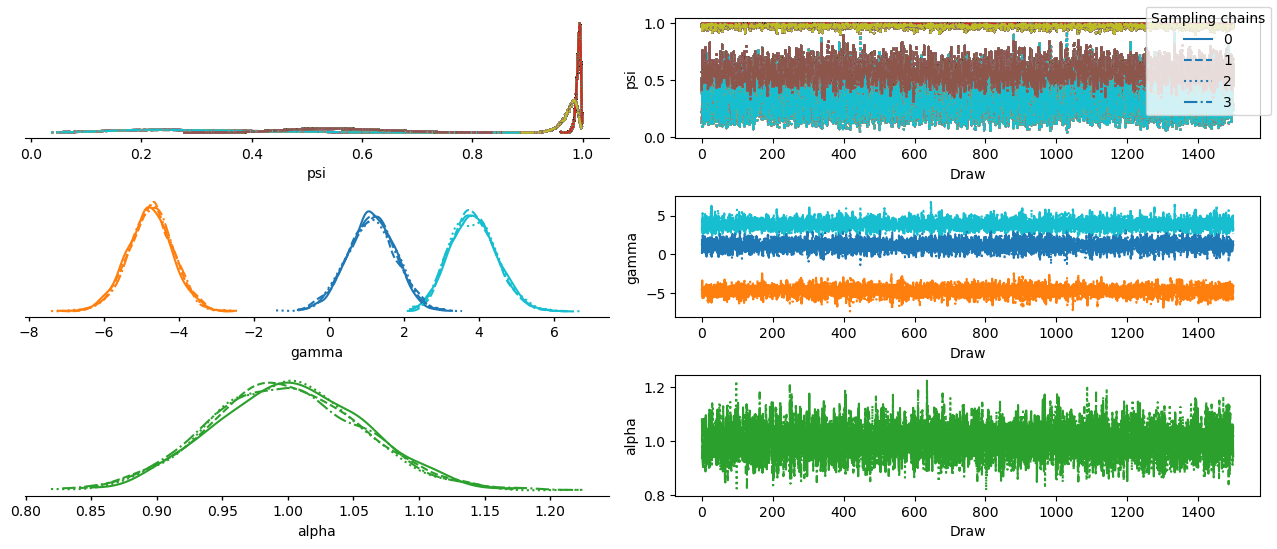

IN-SAMPLE metrics: not a forecast-performance estimate.


c:\Users\yanss\anaconda3\Lib\site-packages\arviz_stats\loo\loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,in_sample_value
n_observations,1249.000000
MAE_predictive_median,46.318655
RMSE_predictive_mean,176.420479
mean_prediction_minus_observed,-6.949108
observed_zero_fraction,0.375500
predicted_zero_fraction,0.334660
zero_event_Brier_score,0.080695
coverage_80,0.900721
coverage_95,0.976781
mean_interval_width_80,141.750440


,value
divergences,0.000000
max_r_hat,1.002298
min_bulk_ESS,4486.118465
min_tail_ESS,3860.773633


,Pearson_residual_ACF
1,0.674204
2,0.618105
3,0.474107
4,0.356553
5,0.258865
6,0.175773
7,0.098883
8,0.027899
9,-0.023275
10,-0.074924


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1249 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -3990.84    92.89
p_loo       57.54        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1248   99.9%
   (0.70, 1]   (bad)         1    0.1%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept_mu],6729,4787,1.00,0.01,0.012
beta[temprange_basis_0],4591,3929,1.00,0.007,0.0063
beta[temprange_basis_1],5823,4759,1.00,0.0081,0.0074
beta[temprange_basis_2],4486,4122,1.00,0.0074,0.007
beta[temprange_basis_3],4753,4214,1.00,0.0061,0.005
beta[temprange_basis_4],6177,4763,1.00,0.0073,0.0065
beta[temprange_basis_5],4858,4554,1.00,0.0061,0.0054
beta[temprange_basis_6],4841,4335,1.00,0.0073,0.0061
beta[temprange_basis_7],6381,4968,1.00,0.0081,0.0071
beta[temprange_basis_8],4848,4508,1.00,0.0075,0.0063



--- Residual diagnostics (ZINB) ---


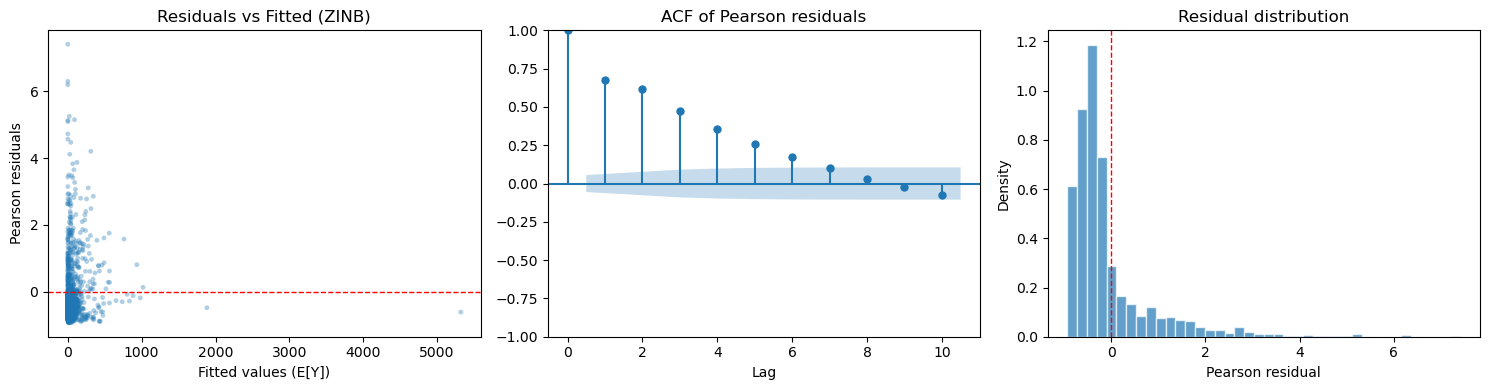

Pearson residual mean   : -0.0605
Pearson residual std    : 0.9603
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.930


In [479]:
# Test 
tar_var = "H1"
exp = mete_col[0]
exp_col_list = [exp]

display(Markdown(f"**{'='*30} {exp} (ZINB) {'='*30}**"))

idata, pred, model_data, cb_list, colnames, nb_result, resid, report = DLNM_ZINB(
    df, max_lag=4,
    tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list,
    bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
    cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=[],
    # PyMC controls – reduce draws/tune for a quick test
    draws=1500, tune=1500, target_accept=0.95, chains=4, cores=4, psi_prior="logistic", prior_sigma=1.0
)


In [480]:
print("Pearson residual summary (from DLNM_ZINB):")
print(f"  mean = {resid.mean():.4f}")
print(f"  std  = {resid.std():.4f}")


Pearson residual summary (from DLNM_ZINB):
  mean = -0.0605
  std  = 0.9603


**============================== temp (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9360.14
BIC for (2, 3, 2, 4): 9382.17
BIC for (2, 3, 3, 3): 9382.17
BIC for (2, 3, 3, 4): 9382.17
BIC for (2, 4, 2, 3): 9376.76
BIC for (2, 4, 2, 4): 9406.18
BIC for (2, 4, 3, 3): 9406.18
BIC for (2, 4, 3, 4): 9406.18
BIC for (3, 3, 2, 3): 9361.96
BIC for (3, 3, 2, 4): 9385.27
BIC for (3, 3, 3, 3): 9385.27
BIC for (3, 3, 3, 4): 9385.27
BIC for (3, 4, 2, 3): 9376.10
BIC for (3, 4, 2, 4): 9406.92
BIC for (3, 4, 3, 3): 9406.92
BIC for (3, 4, 3, 4): 9406.92
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 9360.14)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (25, 4, 8): BIC=8159.4728 | sum(EDF)=45.3427
Degrees of freedom (25, 4, 10): BIC=8169.0760 | sum(EDF)=46.6660
Degrees of freedom (25, 4, 12): BIC=8190.3118 | sum(EDF)=48.0859
Degrees of freedom (25, 4, 14): BIC=8193.3066 | sum(EDF)=48.8966
Degrees of freedom (25, 5, 8): BIC=8159.4728 | sum(EDF)=45.3427
Degrees of freedom (25, 5, 10): BIC=

,alpha,AIC,BIC,GCV,EDF
KFold,"(125.89254117941663, 125.89254117941663, 25.11...",7861.707789,8124.446209,1.087345,51.215083



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   1.5: Pearson ratio = 1.3804 | BIC = 8270.0969
Dispersion   2.0: Pearson ratio = 1.1263 | BIC = 8361.8031
Dispersion   3.0: Pearson ratio = 0.7705 | BIC = 8525.6456
Dispersion   5.0: Pearson ratio = 0.4480 | BIC = 8912.3884

Best dispersion parameter: 2.0 (Pearson ratio = 1.1263)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -6.8231   1.13e+07  -6.05e-07      1.000   -2.21e+07    2.21e+07
temp_basis_0                         -0.4778      0.710     -0.673      0.501      -1.868       0.913
temp_basis_1                         -2.4698      1.289     -1.917      0.055      -4.995       0.056
temp_basis_2                         -1.6779      0.700     -

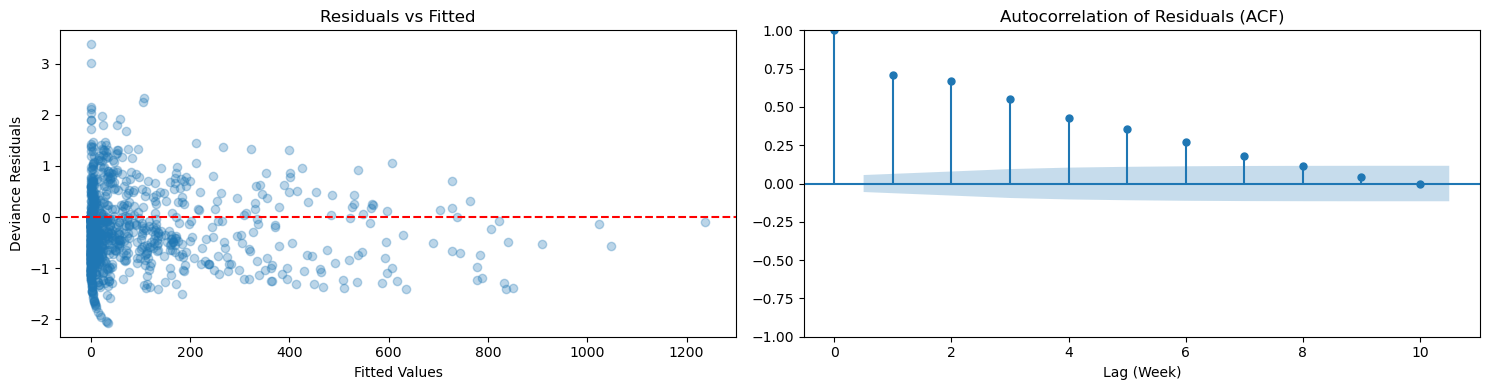

temp RR range: 0.365 to 155.534


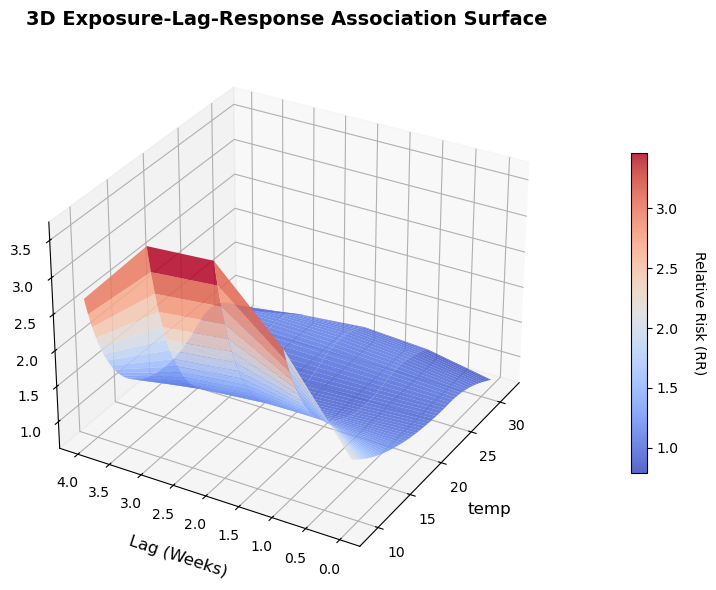

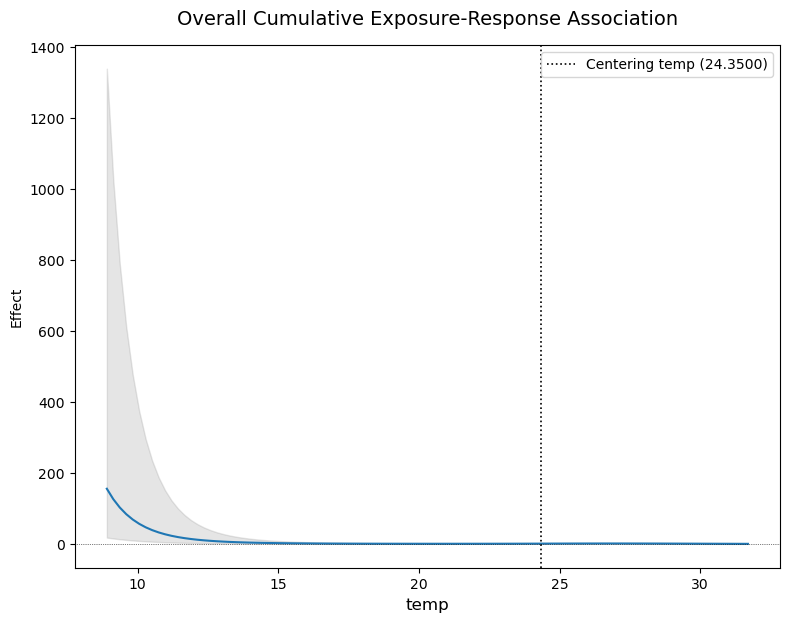

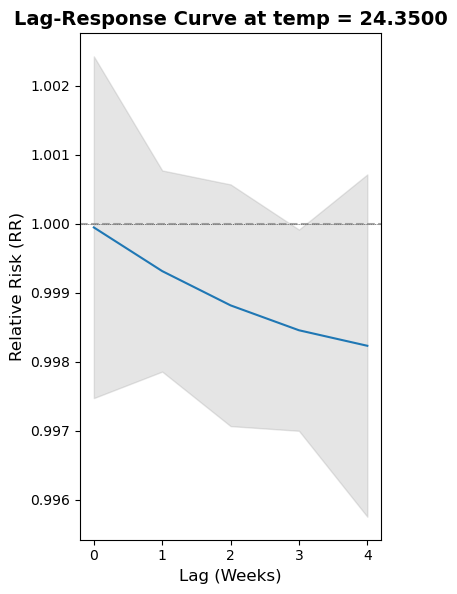

Initializing NUTS using jitter+adapt_diag...



=============== Final PyMC Zero-Inflated Negative Binomial ===============
Sampling separated ZINB model …


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 179 seconds.


Output()

===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.993,0.004,0.986,0.998,6979.739,4718.915,1.000,0.000,0.000
psi[1],0.993,0.004,0.986,0.998,6979.739,4718.915,1.000,0.000,0.000
psi[2],0.993,0.004,0.986,0.998,6979.739,4718.915,1.000,0.000,0.000
psi[3],0.993,0.004,0.986,0.998,6979.739,4718.915,1.000,0.000,0.000
psi[4],0.993,0.004,0.986,0.998,6979.739,4718.915,1.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...
beta[Week_s10],-1.232,0.211,-1.569,-0.890,5654.763,4695.286,1.001,0.003,0.003
gamma[intercept_psi],3.887,0.608,2.956,4.870,5382.878,4143.554,1.001,0.008,0.011
gamma[school_flag],1.197,0.639,0.168,2.233,6146.731,4604.308,1.000,0.008,0.008
gamma[pandemic_flag],-4.714,0.641,-5.732,-3.749,5979.060,4328.796,1.002,0.009,0.017


temp RR range: 0.689 to 81.801


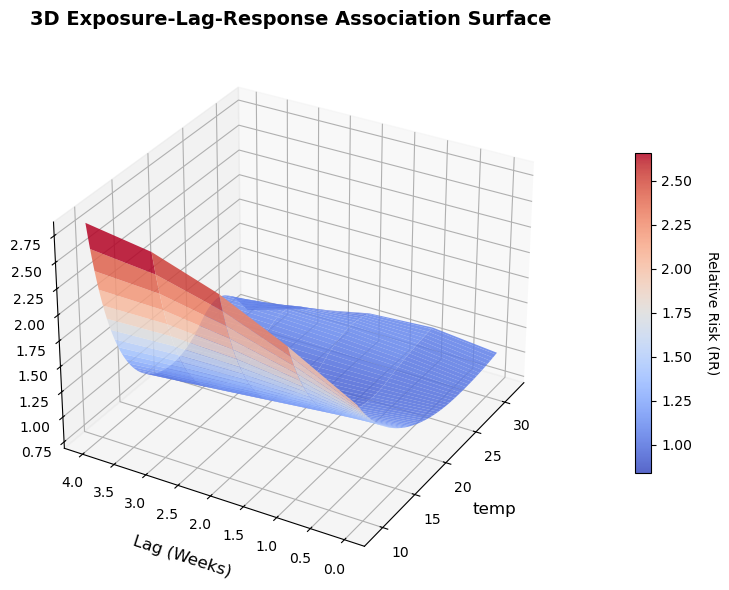

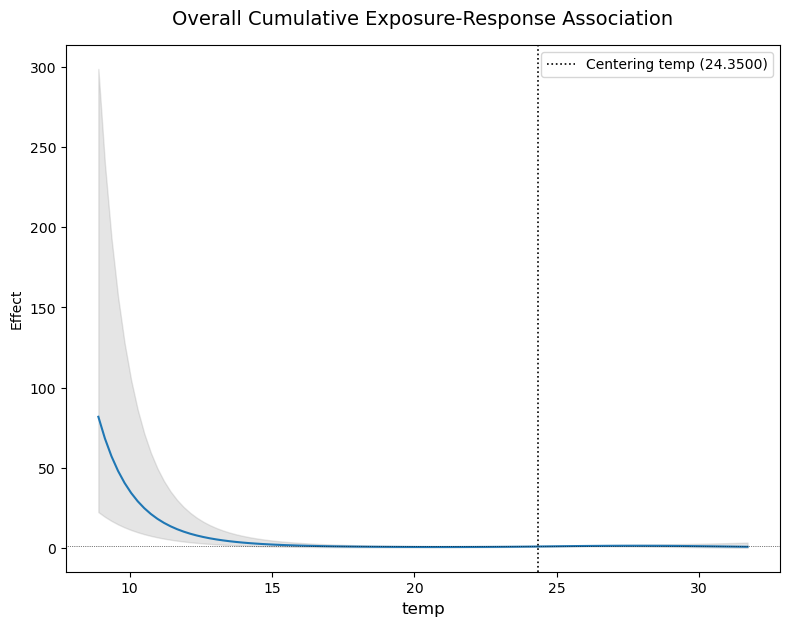

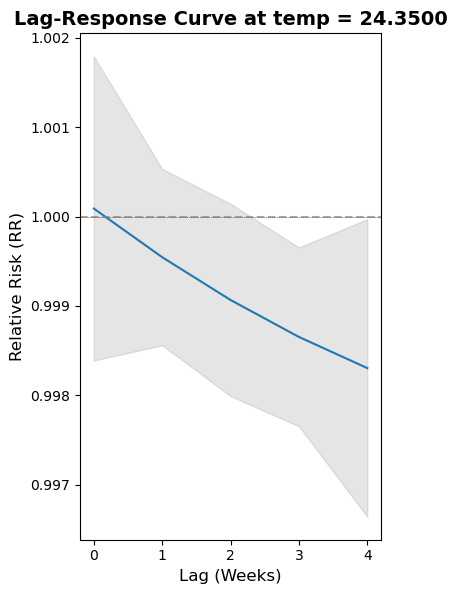

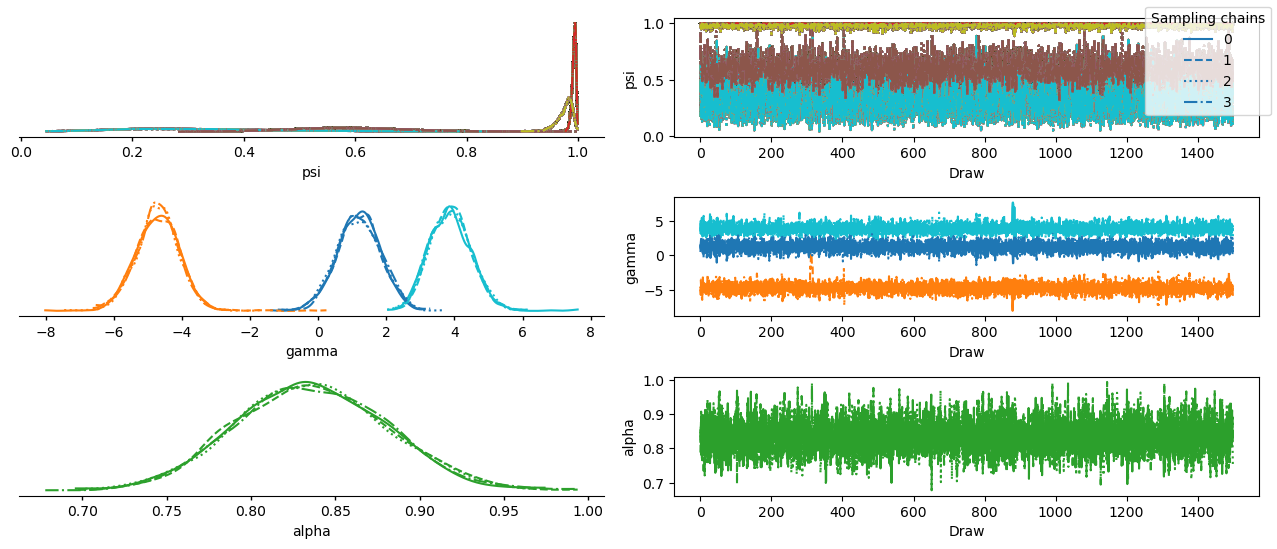

IN-SAMPLE metrics: not a forecast-performance estimate.


,in_sample_value
n_observations,1249.000000
MAE_predictive_median,51.937950
RMSE_predictive_mean,145.090567
mean_prediction_minus_observed,-5.093852
observed_zero_fraction,0.375500
predicted_zero_fraction,0.340470
zero_event_Brier_score,0.077924
coverage_80,0.917534
coverage_95,0.971177
mean_interval_width_80,155.458927


,value
divergences,0.000000
max_r_hat,1.002039
min_bulk_ESS,2664.013207
min_tail_ESS,3097.536163


,Pearson_residual_ACF
1,0.718658
2,0.685274
3,0.528925
4,0.425214
5,0.290970
6,0.209472
7,0.139381
8,0.063954
9,0.014108
10,-0.028467


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1249 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4054.98    94.77
p_loo       50.88        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1249  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept_mu],5236,4452,1.00,0.0096,0.0089
beta[temp_basis_0],6061,5088,1.00,0.0054,0.0047
beta[temp_basis_1],6011,4854,1.00,0.0081,0.008
beta[temp_basis_2],4976,4440,1.00,0.0062,0.0053
beta[temp_basis_3],3754,4094,1.00,0.006,0.0044
beta[temp_basis_4],5358,4480,1.00,0.0077,0.0066
beta[temp_basis_5],4410,4411,1.00,0.0055,0.0043
beta[temp_basis_6],4739,4830,1.00,0.006,0.0044
beta[temp_basis_7],5892,5129,1.00,0.008,0.0065
beta[temp_basis_8],5061,4675,1.00,0.006,0.0049



--- Residual diagnostics (ZINB) ---


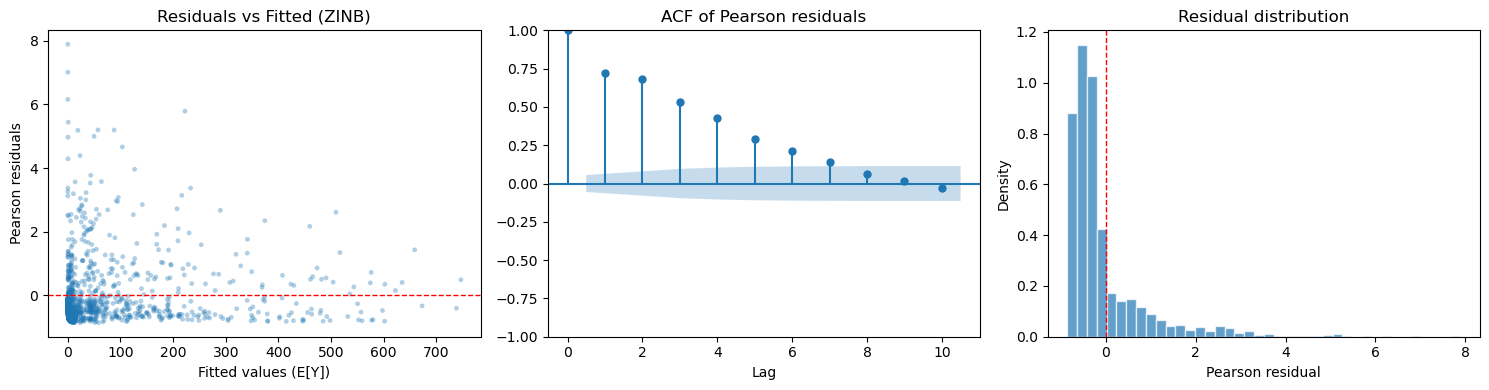

Pearson residual mean   : -0.0569
Pearson residual std    : 0.9911
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.935


**============================== RH (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9704.56
BIC for (2, 3, 2, 4): 9723.98
BIC for (2, 3, 3, 3): 9723.98
BIC for (2, 3, 3, 4): 9723.98
BIC for (2, 4, 2, 3): 9681.16
BIC for (2, 4, 2, 4): 9705.08
BIC for (2, 4, 3, 3): 9705.08
BIC for (2, 4, 3, 4): 9705.08
BIC for (3, 3, 2, 3): 9693.76
BIC for (3, 3, 2, 4): 9712.80
BIC for (3, 3, 3, 3): 9712.80
BIC for (3, 3, 3, 4): 9712.80
BIC for (3, 4, 2, 3): 9677.14
BIC for (3, 4, 2, 4): 9699.58
BIC for (3, 4, 3, 3): 9699.58
BIC for (3, 4, 3, 4): 9699.58
Best CrossBasis setting: (3, 4, 2, 3) (BIC = 9677.14)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (25, 4, 8): BIC=8184.9691 | sum(EDF)=49.0767
Degrees of freedom (25, 4, 10): BIC=8185.3281 | sum(EDF)=50.7116
Degrees of freedom (25, 4, 12): BIC=8188.5413 | sum(EDF)=52.0321
Degrees of freedom (25, 4, 14): BIC=8193.3446 | sum(EDF)=52.8478
Degrees of freedom (25, 5, 8): BIC=8184.9691 | sum(EDF)=49.0767
Degrees of freedom (25, 5, 10): BIC=

,alpha,AIC,BIC,GCV,EDF
KFold,"(1.0, 125.89254117941663, 25.118864315095795)",7659.359392,7999.753509,1.115358,66.352355



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   1.5: Pearson ratio = 2.5456 | BIC = 8079.9528
Dispersion   2.0: Pearson ratio = 0.7973 | BIC = 8261.6921
Dispersion   3.0: Pearson ratio = 0.4447 | BIC = 8528.9543
Dispersion   5.0: Pearson ratio = 0.2871 | BIC = 8956.3552

Best dispersion parameter: 2.0 (Pearson ratio = 0.7973)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -9.1558   9.61e+06  -9.53e-07      1.000   -1.88e+07    1.88e+07
RH_basis_0                           -0.8665      1.229     -0.705      0.481      -3.276       1.543
RH_basis_1                           -1.9057      2.120     -0.899      0.369      -6.060       2.249
RH_basis_2                           -2.0596      1.220     -

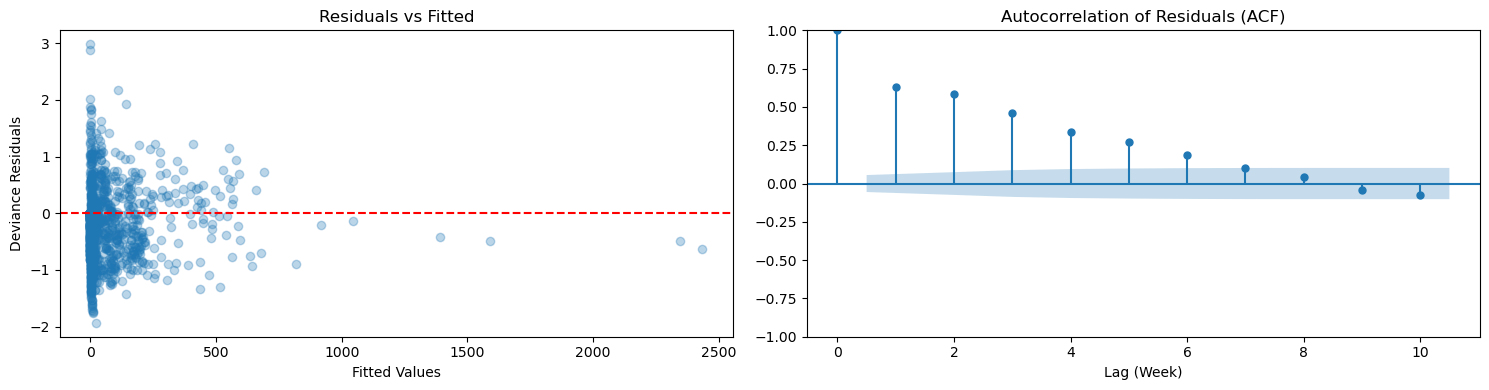

RH RR range: 0.331 to 42.495


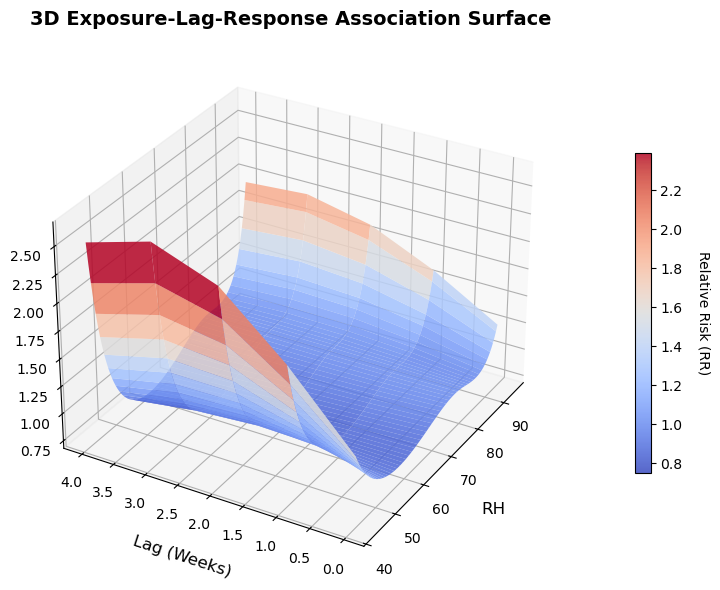

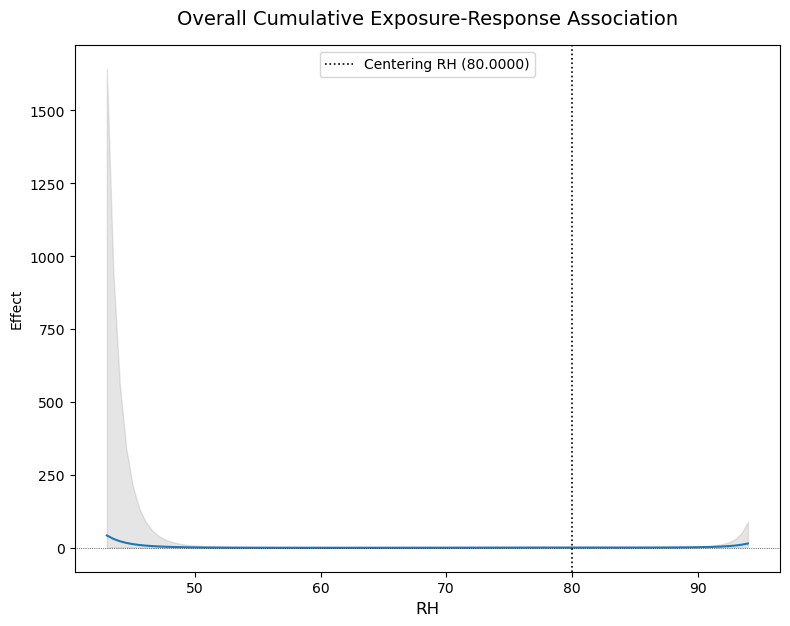

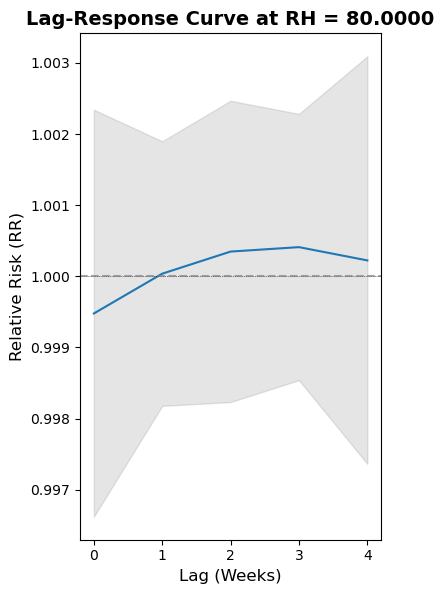

Initializing NUTS using jitter+adapt_diag...



=============== Final PyMC Zero-Inflated Negative Binomial ===============
Sampling separated ZINB model …


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 184 seconds.


Output()

===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.996,0.004,0.989,1.000,2449.750,3228.948,1.002,0.000,0.000
psi[1],0.996,0.004,0.989,1.000,2449.750,3228.948,1.002,0.000,0.000
psi[2],0.996,0.004,0.989,1.000,2449.750,3228.948,1.002,0.000,0.000
psi[3],0.996,0.004,0.989,1.000,2449.750,3228.948,1.002,0.000,0.000
psi[4],0.996,0.004,0.989,1.000,2449.750,3228.948,1.002,0.000,0.000
...,...,...,...,...,...,...,...,...,...
beta[Week_s12],-1.049,0.167,-1.311,-0.780,5838.857,4599.965,1.001,0.002,0.002
gamma[intercept_psi],4.132,0.737,3.059,5.387,6173.963,4414.415,1.001,0.010,0.010
gamma[school_flag],1.679,0.989,0.240,3.410,3762.914,3260.939,1.001,0.017,0.013
gamma[pandemic_flag],-2.052,2.381,-5.211,1.820,1455.451,2907.577,1.002,0.065,0.015


RH RR range: 0.624 to 65.671


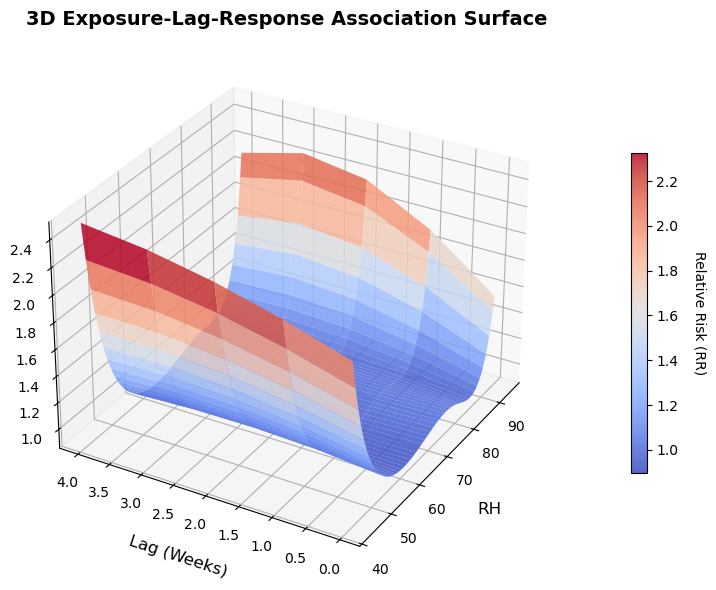

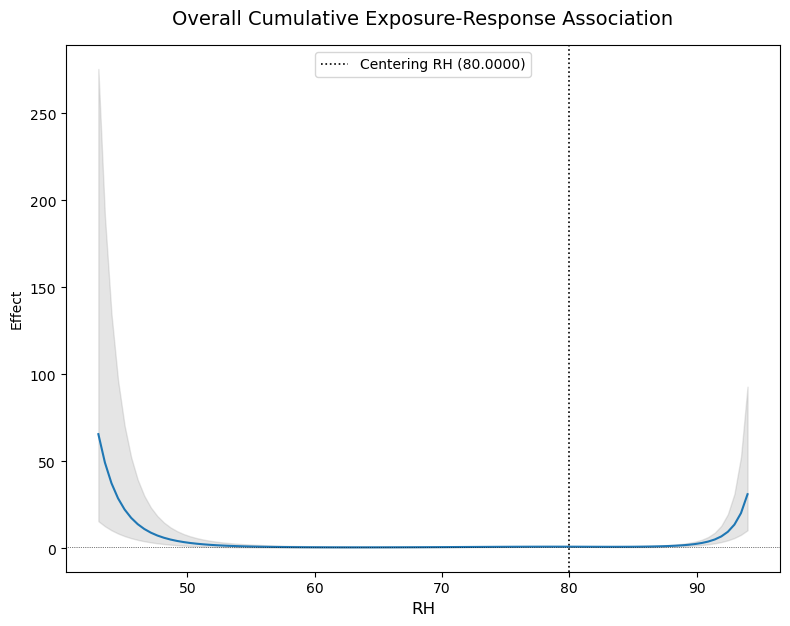

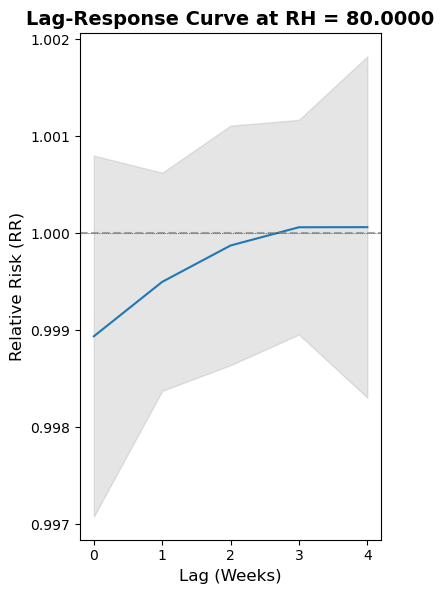

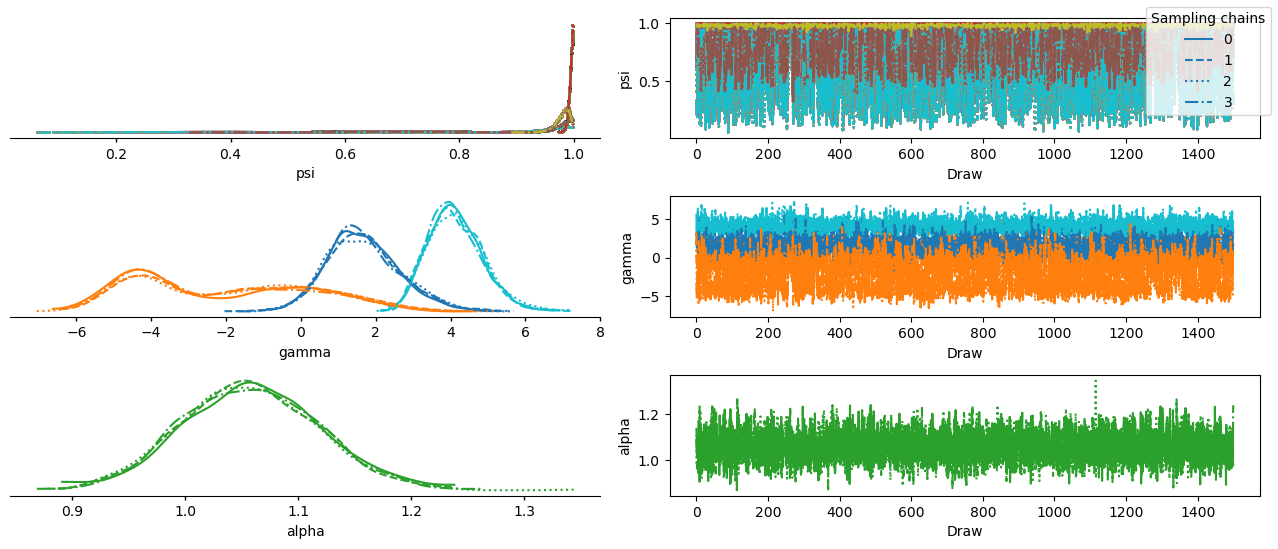

IN-SAMPLE metrics: not a forecast-performance estimate.


c:\Users\yanss\anaconda3\Lib\site-packages\arviz_stats\loo\loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,in_sample_value
n_observations,1249.000000
MAE_predictive_median,45.434347
RMSE_predictive_mean,126.789923
mean_prediction_minus_observed,-11.028375
observed_zero_fraction,0.375500
predicted_zero_fraction,0.330110
zero_event_Brier_score,0.071688
coverage_80,0.907926
coverage_95,0.979183
mean_interval_width_80,131.082626


,value
divergences,0.000000
max_r_hat,1.002399
min_bulk_ESS,1455.451090
min_tail_ESS,2605.514927


,Pearson_residual_ACF
1,0.643759
2,0.570061
3,0.434822
4,0.302003
5,0.214931
6,0.137490
7,0.064733
8,0.009410
9,-0.034915
10,-0.074573


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1249 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -3955.03    92.91
p_loo       69.90        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1248   99.9%
   (0.70, 1]   (bad)         1    0.1%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept_mu],5148,4003,1.00,0.01,0.01
beta[RH_basis_0],4461,4200,1.00,0.008,0.0065
beta[RH_basis_1],5134,4693,1.00,0.0097,0.0085
beta[RH_basis_2],4450,3933,1.00,0.0077,0.006
beta[RH_basis_3],4255,4363,1.00,0.0055,0.0042
beta[RH_basis_4],5414,4525,1.00,0.0069,0.0063
beta[RH_basis_5],4784,4240,1.00,0.0049,0.0039
beta[RH_basis_6],4019,4091,1.00,0.0058,0.0046
beta[RH_basis_7],4784,4401,1.00,0.007,0.0059
beta[RH_basis_8],4084,4137,1.00,0.0055,0.0041



--- Residual diagnostics (ZINB) ---


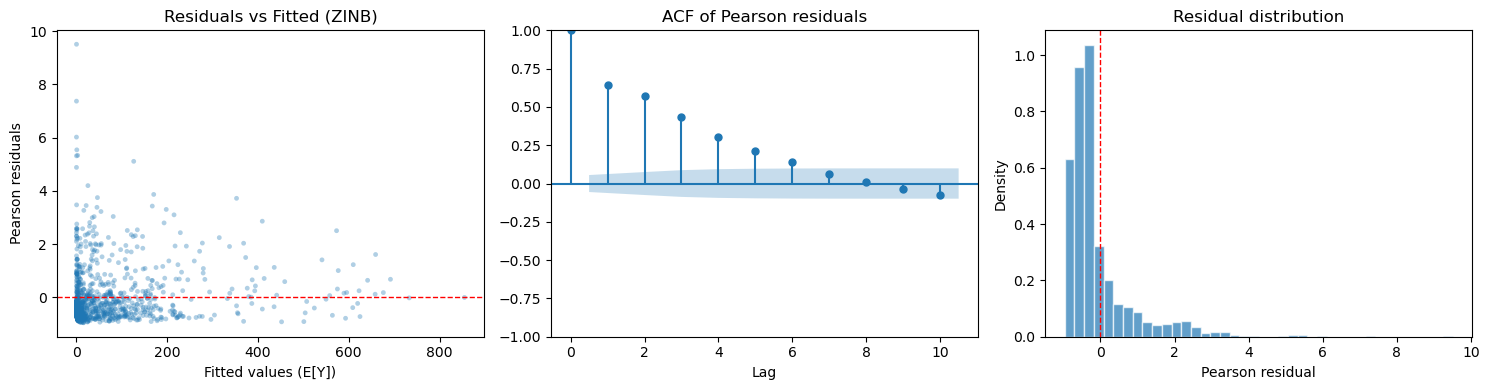

Pearson residual mean   : -0.0678
Pearson residual std    : 0.9769
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.974


**============================== SR (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9648.68
BIC for (2, 3, 2, 4): 9671.72
BIC for (2, 3, 3, 3): 9671.72
BIC for (2, 3, 3, 4): 9671.72
BIC for (2, 4, 2, 3): 9666.74
BIC for (2, 4, 2, 4): 9696.20
BIC for (2, 4, 3, 3): 9696.20
BIC for (2, 4, 3, 4): 9696.20
BIC for (3, 3, 2, 3): 9648.09
BIC for (3, 3, 2, 4): 9670.84
BIC for (3, 3, 3, 3): 9670.84
BIC for (3, 3, 3, 4): 9670.84
BIC for (3, 4, 2, 3): 9663.18
BIC for (3, 4, 2, 4): 9692.20
BIC for (3, 4, 3, 3): 9692.20
BIC for (3, 4, 3, 4): 9692.20
Best CrossBasis setting: (3, 3, 2, 3) (BIC = 9648.09)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (25, 4, 8): BIC=8138.2226 | sum(EDF)=45.2535
Degrees of freedom (25, 4, 10): BIC=8137.4247 | sum(EDF)=46.7988
Degrees of freedom (25, 4, 12): BIC=8141.5747 | sum(EDF)=48.1616
Degrees of freedom (25, 4, 14): BIC=8146.5300 | sum(EDF)=48.9886
Degrees of freedom (25, 5, 8): BIC=8138.2226 | sum(EDF)=45.2535
Degrees of freedom (25, 5, 10): BIC=

,alpha,AIC,BIC,GCV,EDF
KFold,"(1.0, 25.118864315095795, 1.0)",7721.783741,8020.265307,1.100106,58.182424



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   1.5: Pearson ratio = 2264.9086 | BIC = 8137.8895
Dispersion   2.0: Pearson ratio = 192.8685 | BIC = 8271.3491
Dispersion   3.0: Pearson ratio = 7.1920 | BIC = 8522.8046
Dispersion   5.0: Pearson ratio = 0.4873 | BIC = 8933.7031

Best dispersion parameter: 5.0 (Pearson ratio = 0.4873)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                           -21.1402      8.208     -2.575      0.010     -37.228      -5.052
SR_basis_0                           -0.3886      1.263     -0.308      0.758      -2.864       2.086
SR_basis_1                           -1.1149      2.209     -0.505      0.614      -5.444       3.214
SR_basis_2                           -0.5478      1.287 

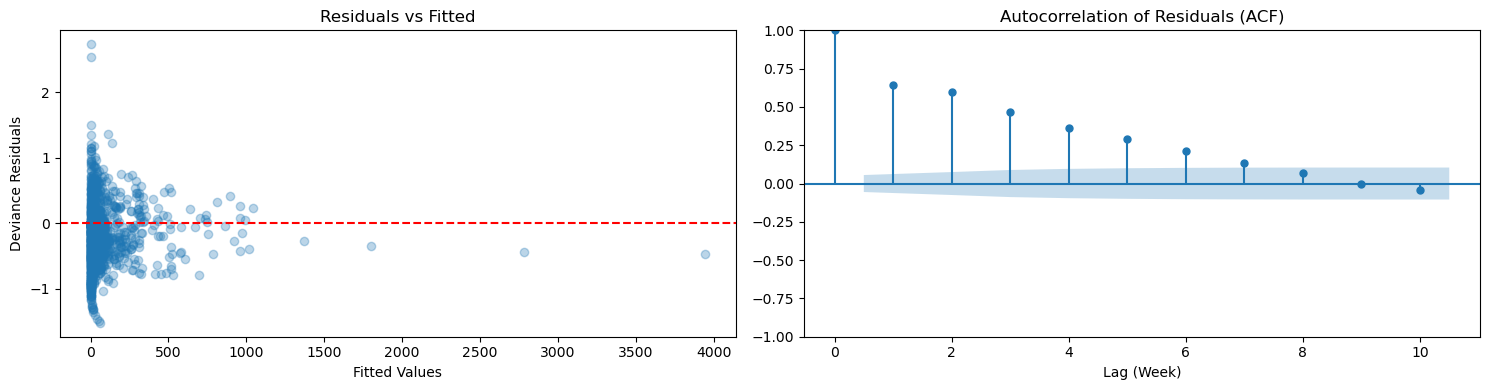

SR RR range: 0.376 to 9.720


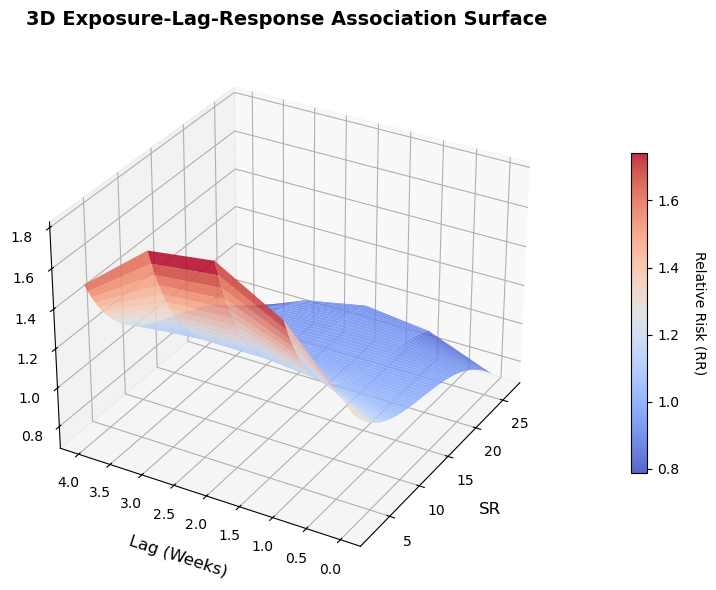

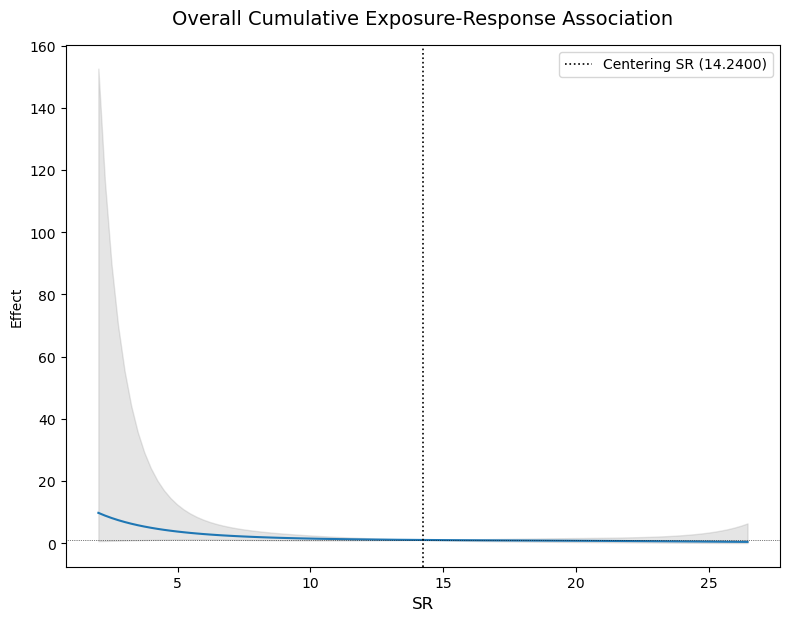

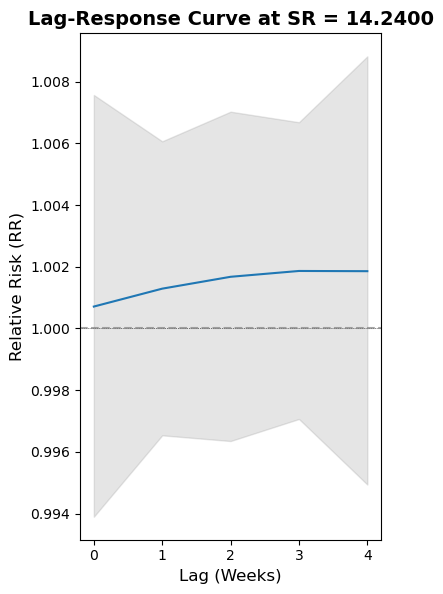


=============== Final PyMC Zero-Inflated Negative Binomial ===============
Sampling separated ZINB model …


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 166 seconds.


Output()

===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.992,0.004,0.984,0.997,7410.204,4602.523,1.000,0.000,0.000
psi[1],0.992,0.004,0.984,0.997,7410.204,4602.523,1.000,0.000,0.000
psi[2],0.992,0.004,0.984,0.997,7410.204,4602.523,1.000,0.000,0.000
psi[3],0.992,0.004,0.984,0.997,7410.204,4602.523,1.000,0.000,0.000
psi[4],0.992,0.004,0.984,0.997,7410.204,4602.523,1.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...
beta[Week_s10],-1.421,0.153,-1.667,-1.178,7817.729,4879.398,1.002,0.002,0.002
gamma[intercept_psi],3.812,0.607,2.886,4.829,5476.412,4015.826,1.001,0.008,0.008
gamma[school_flag],1.136,0.652,0.102,2.153,5864.303,4824.546,1.001,0.009,0.009
gamma[pandemic_flag],-4.462,0.740,-5.525,-3.448,4638.661,3359.797,1.001,0.017,0.050


SR RR range: 0.282 to 38.391


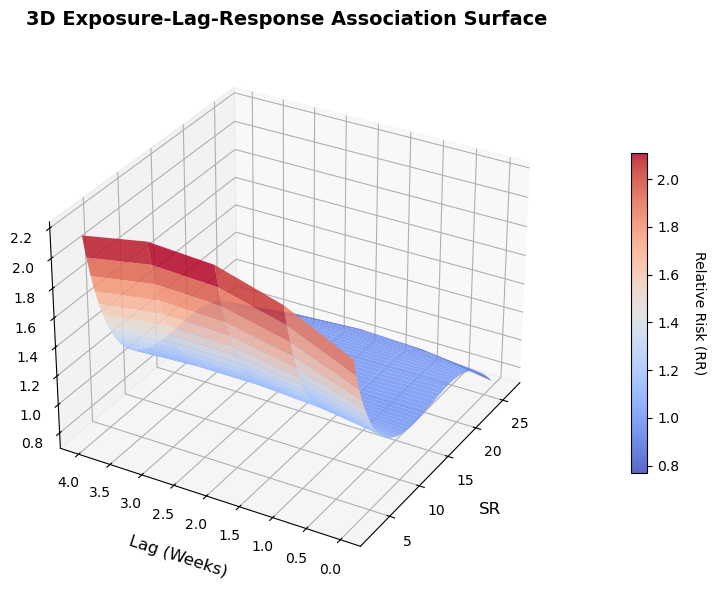

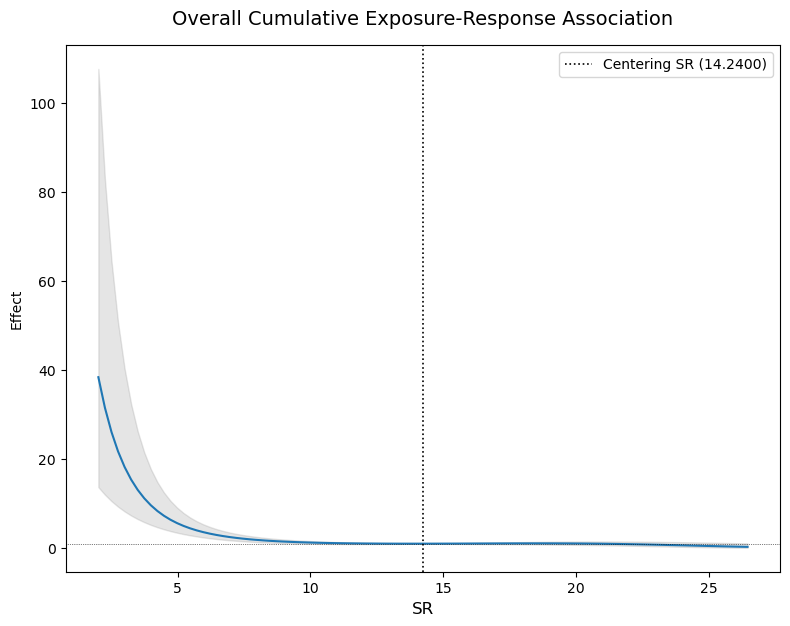

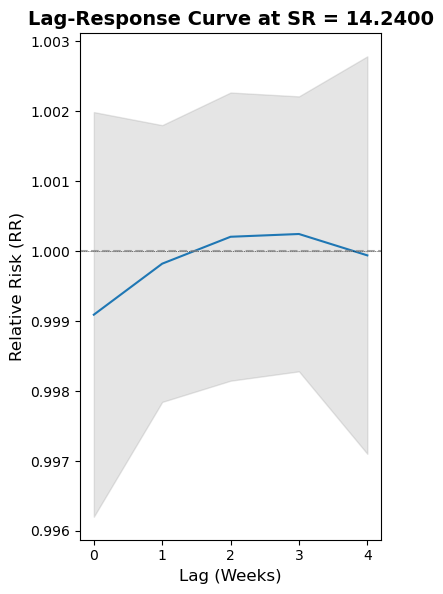

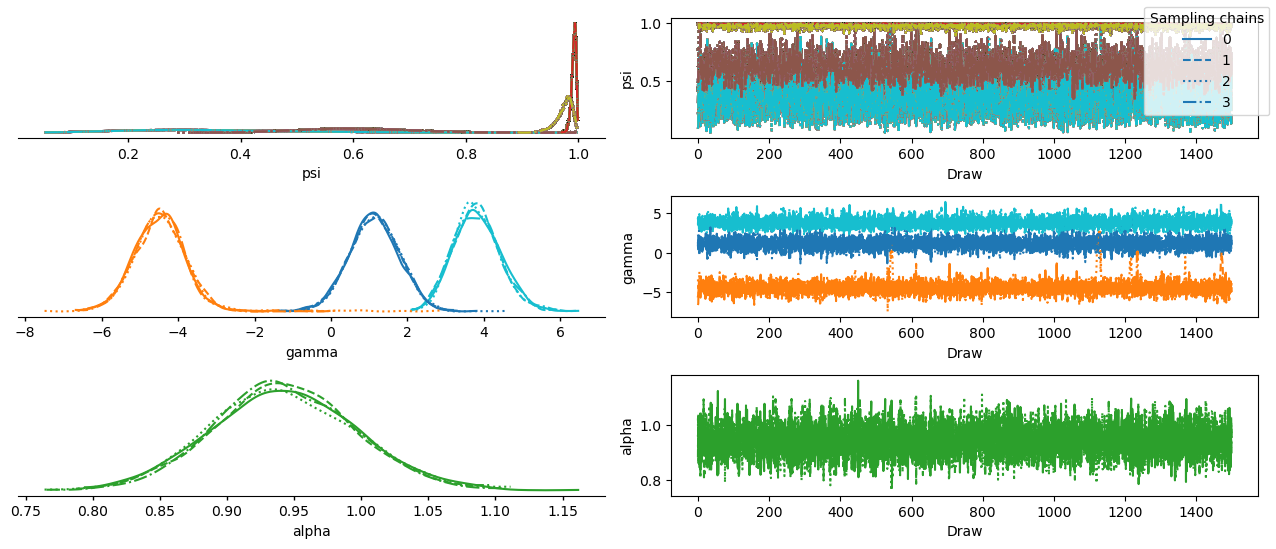

IN-SAMPLE metrics: not a forecast-performance estimate.


c:\Users\yanss\anaconda3\Lib\site-packages\arviz_stats\loo\loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,in_sample_value
n_observations,1249.000000
MAE_predictive_median,48.769015
RMSE_predictive_mean,134.375303
mean_prediction_minus_observed,-7.341363
observed_zero_fraction,0.375500
predicted_zero_fraction,0.334001
zero_event_Brier_score,0.082143
coverage_80,0.907126
coverage_95,0.972778
mean_interval_width_80,144.274700


,value
divergences,0.000000
max_r_hat,1.002328
min_bulk_ESS,3291.115066
min_tail_ESS,3359.796594


,Pearson_residual_ACF
1,0.711268
2,0.642301
3,0.505536
4,0.386261
5,0.269655
6,0.199357
7,0.130140
8,0.047996
9,-0.008746
10,-0.061020


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1249 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -4008.99    93.07
p_loo       54.19        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1247   99.8%
   (0.70, 1]   (bad)         2    0.2%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept_mu],4068,4066,1.00,0.01,0.0079
beta[SR_basis_0],3800,3588,1.00,0.0077,0.0053
beta[SR_basis_1],5470,4596,1.00,0.0089,0.0071
beta[SR_basis_2],3994,4122,1.00,0.0075,0.0056
beta[SR_basis_3],5692,4918,1.00,0.0038,0.0033
beta[SR_basis_4],6203,4638,1.00,0.0057,0.0053
beta[SR_basis_5],6331,5071,1.00,0.0036,0.0032
beta[SR_basis_6],3561,3742,1.00,0.0058,0.004
beta[SR_basis_7],4330,4645,1.00,0.0075,0.0054
beta[SR_basis_8],3710,4034,1.00,0.0056,0.0042



--- Residual diagnostics (ZINB) ---


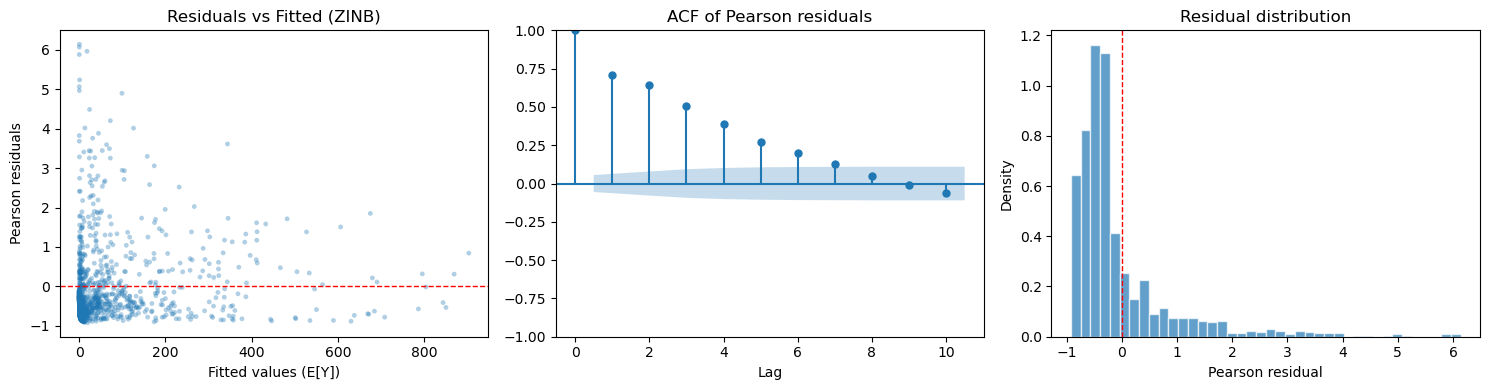

Pearson residual mean   : -0.0634
Pearson residual std    : 0.9629
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.937


**============================== AP (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9510.65
BIC for (2, 3, 2, 4): 9533.23
BIC for (2, 3, 3, 3): 9533.23
BIC for (2, 3, 3, 4): 9533.23
BIC for (2, 4, 2, 3): 9540.51
BIC for (2, 4, 2, 4): 9569.54
BIC for (2, 4, 3, 3): 9569.54
BIC for (2, 4, 3, 4): 9569.54
BIC for (3, 3, 2, 3): 9531.36
BIC for (3, 3, 2, 4): 9555.13
BIC for (3, 3, 3, 3): 9555.13
BIC for (3, 3, 3, 4): 9555.13
BIC for (3, 4, 2, 3): 9551.98
BIC for (3, 4, 2, 4): 9587.16
BIC for (3, 4, 3, 3): 9587.16
BIC for (3, 4, 3, 4): 9587.16
Best CrossBasis setting: (2, 3, 2, 3) (BIC = 9510.65)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (25, 4, 8): BIC=8210.6900 | sum(EDF)=46.0138
Degrees of freedom (25, 4, 10): BIC=8213.5592 | sum(EDF)=47.5417
Degrees of freedom (25, 4, 12): BIC=8219.6651 | sum(EDF)=48.7439
Degrees of freedom (25, 4, 14): BIC=8225.2394 | sum(EDF)=49.5491
Degrees of freedom (25, 5, 8): BIC=8210.6900 | sum(EDF)=46.0138
Degrees of freedom (25, 5, 10): BIC=

,alpha,AIC,BIC,GCV,EDF
KFold,"(5.011872336272722, 125.89254117941663, 5.0118...",7708.334556,8036.567261,1.1109,63.981755



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   1.5: Pearson ratio = 1.1280 | BIC = 8147.2284
Dispersion   2.0: Pearson ratio = 0.6557 | BIC = 8278.9611
Dispersion   3.0: Pearson ratio = 0.4415 | BIC = 8550.5974
Dispersion   5.0: Pearson ratio = 0.2950 | BIC = 8964.0619

Best dispersion parameter: 1.5 (Pearson ratio = 1.1280)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                           -10.4526      5.223     -2.001      0.045     -20.689      -0.216
AP_basis_0                            0.3463      0.577      0.600      0.549      -0.785       1.478
AP_basis_1                            1.4010      0.983      1.425      0.154      -0.526       3.328
AP_basis_2                            0.1424      0.582      

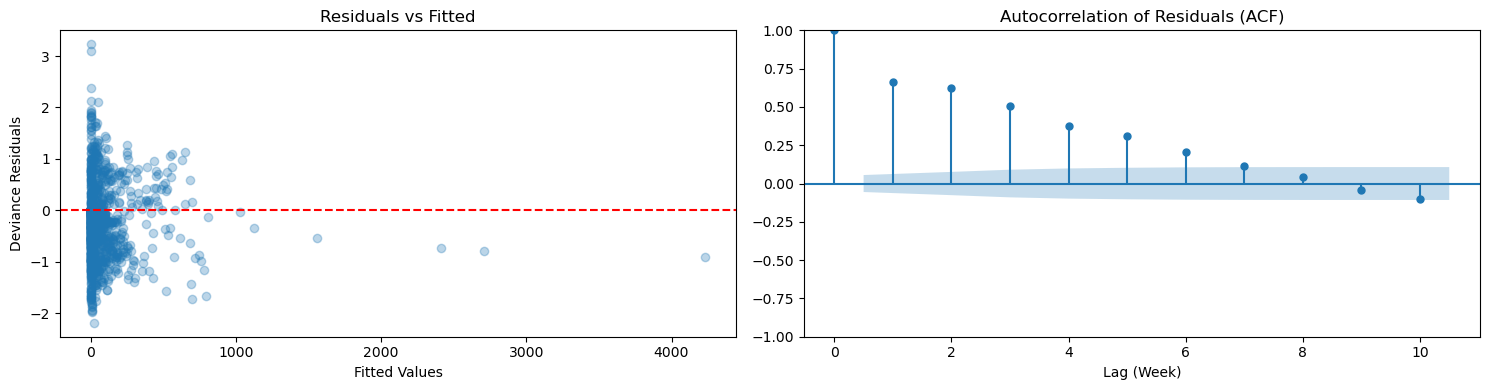

AP RR range: 0.356 to 1.861


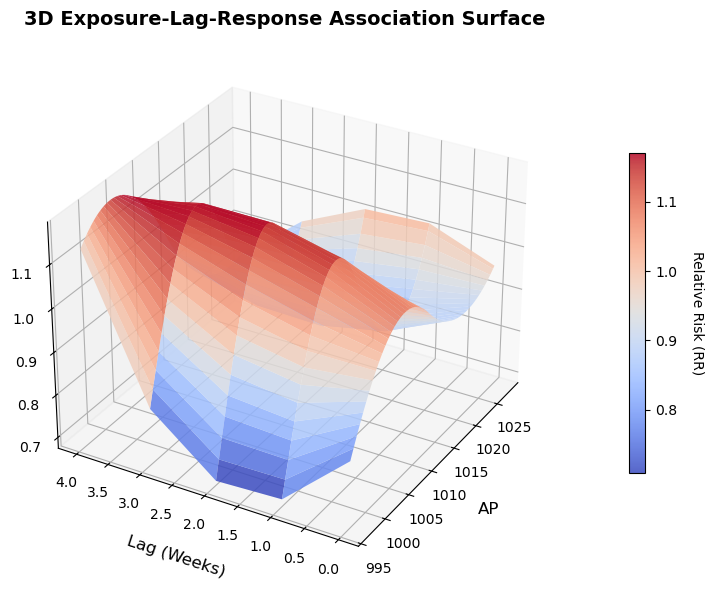

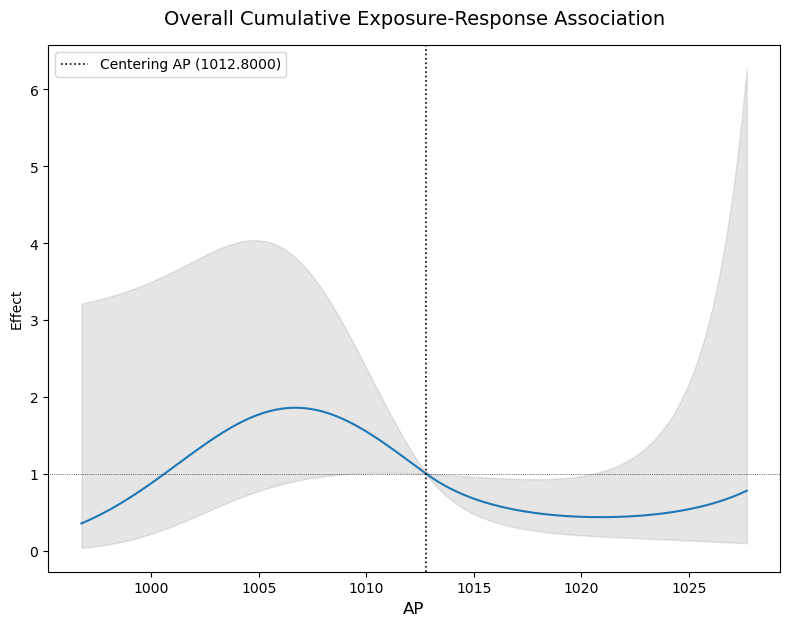

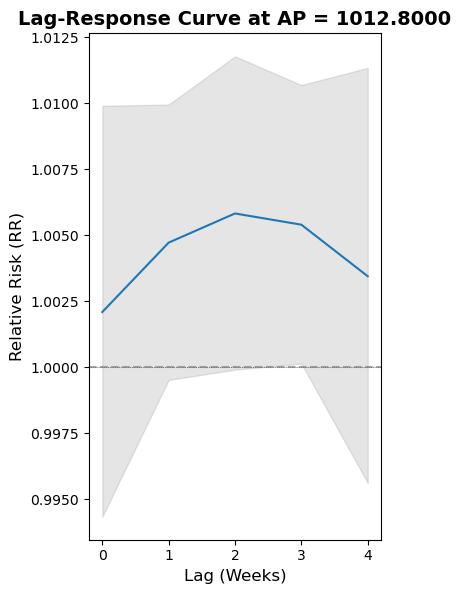


=============== Final PyMC Zero-Inflated Negative Binomial ===============
Sampling separated ZINB model …


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 231 seconds.


Output()

===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.994,0.004,0.987,0.998,2101.972,1447.322,1.002,0.000,0.000
psi[1],0.994,0.004,0.987,0.998,2101.972,1447.322,1.002,0.000,0.000
psi[2],0.994,0.004,0.987,0.998,2101.972,1447.322,1.002,0.000,0.000
psi[3],0.994,0.004,0.987,0.998,2101.972,1447.322,1.002,0.000,0.000
psi[4],0.994,0.004,0.987,0.998,2101.972,1447.322,1.002,0.000,0.000
...,...,...,...,...,...,...,...,...,...
beta[Week_s10],-1.202,0.196,-1.511,-0.887,2482.238,3369.831,1.001,0.004,0.002
gamma[intercept_psi],3.990,0.657,3.020,5.113,5071.778,3295.836,1.001,0.010,0.010
gamma[school_flag],1.267,0.752,0.097,2.456,3491.143,2496.714,1.001,0.014,0.015
gamma[pandemic_flag],-4.149,1.500,-5.581,-0.577,767.303,370.046,1.005,0.074,0.086


AP RR range: 0.920 to 4.099


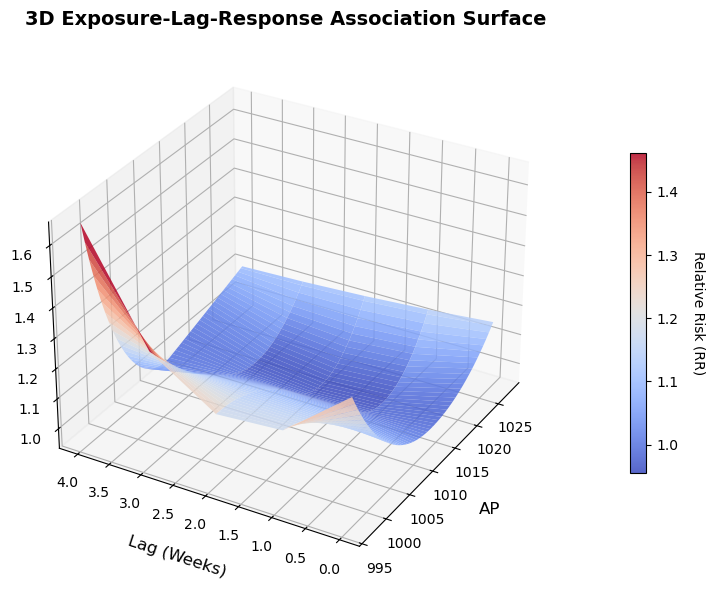

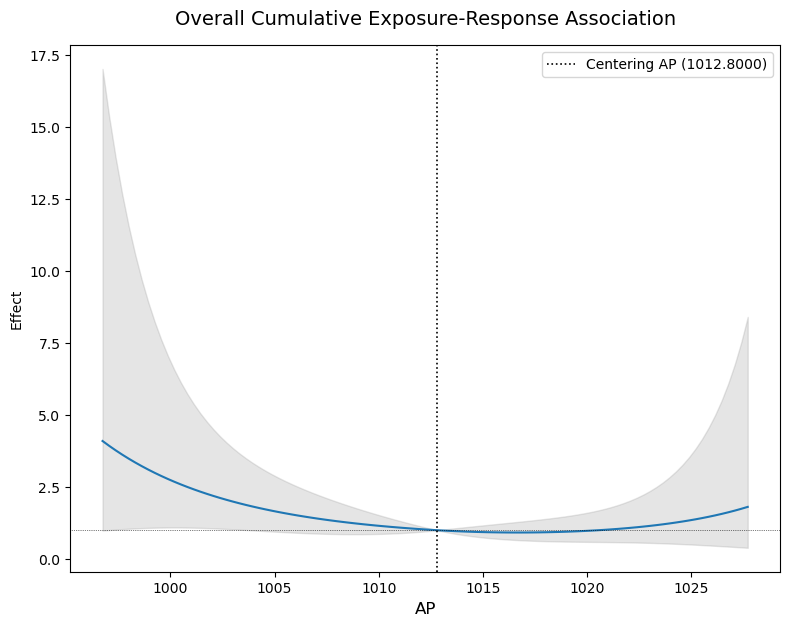

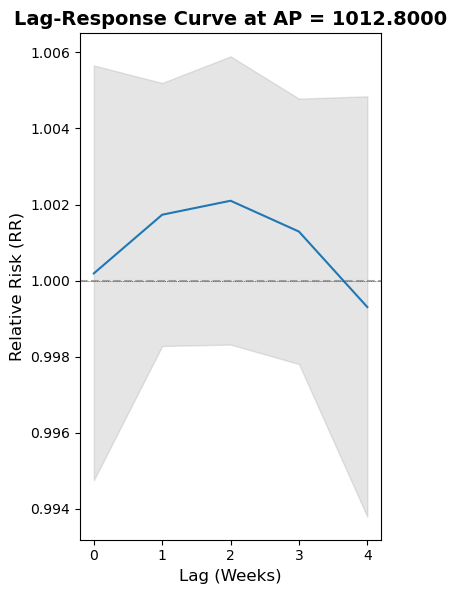

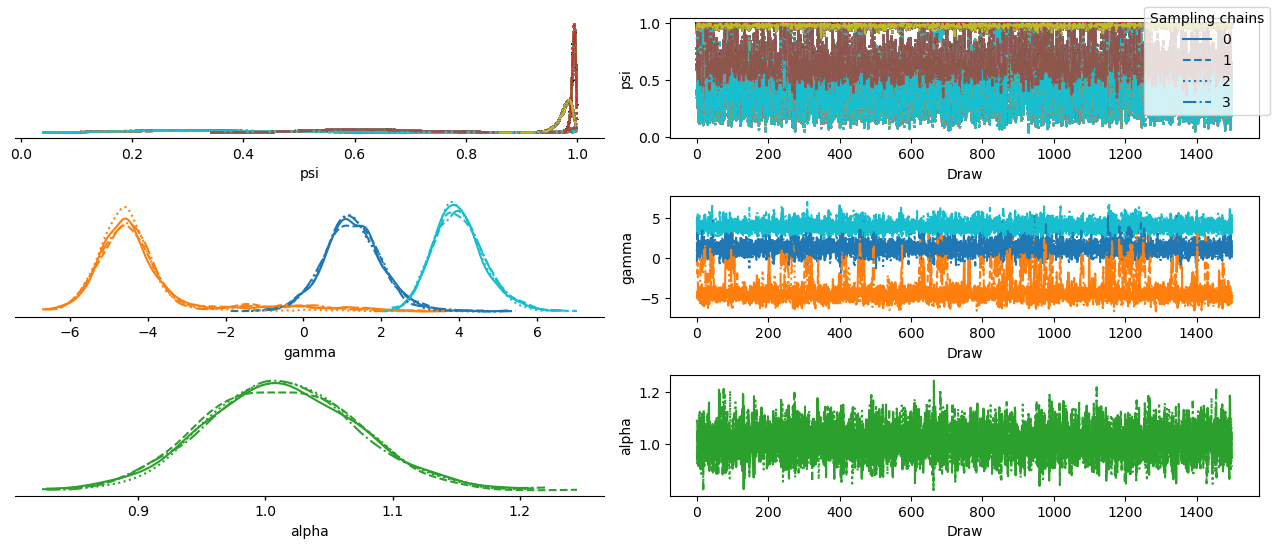

IN-SAMPLE metrics: not a forecast-performance estimate.


c:\Users\yanss\anaconda3\Lib\site-packages\arviz_stats\loo\loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,in_sample_value
n_observations,1249.000000
MAE_predictive_median,47.465172
RMSE_predictive_mean,134.503450
mean_prediction_minus_observed,-9.505460
observed_zero_fraction,0.375500
predicted_zero_fraction,0.334405
zero_event_Brier_score,0.073157
coverage_80,0.899119
coverage_95,0.983987
mean_interval_width_80,135.796157


,value
divergences,0.000000
max_r_hat,1.005270
min_bulk_ESS,767.302867
min_tail_ESS,370.045528


,Pearson_residual_ACF
1,0.692443
2,0.613955
3,0.475930
4,0.345032
5,0.253186
6,0.170209
7,0.098870
8,0.033877
9,-0.020281
10,-0.074930


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1249 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -3974.77    93.25
p_loo       63.95        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1248   99.9%
   (0.70, 1]   (bad)         1    0.1%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept_mu],4738,3947,1.00,0.01,0.0098
beta[AP_basis_0],4560,4226,1.00,0.0055,0.0048
beta[AP_basis_1],5380,4710,1.00,0.0073,0.0062
beta[AP_basis_2],4383,4138,1.00,0.0055,0.0045
beta[AP_basis_3],3590,4232,1.00,0.0055,0.0037
beta[AP_basis_4],5613,4448,1.00,0.0069,0.0061
beta[AP_basis_5],4060,4379,1.00,0.0052,0.004
beta[AP_basis_6],4466,4297,1.00,0.0057,0.0048
beta[AP_basis_7],5624,4586,1.00,0.0075,0.0068
beta[AP_basis_8],4558,4506,1.00,0.0055,0.0044



--- Residual diagnostics (ZINB) ---


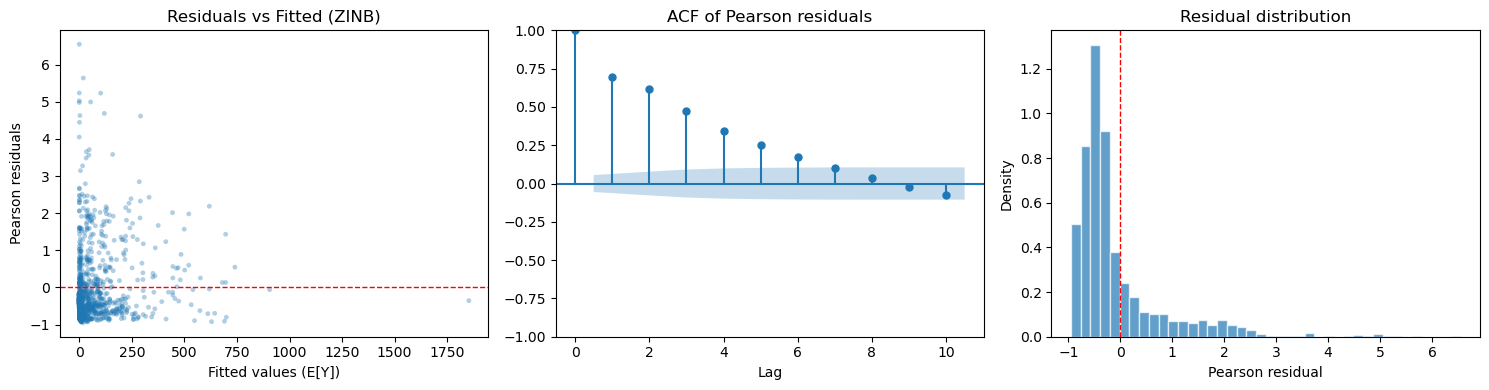

Pearson residual mean   : -0.0743
Pearson residual std    : 0.9326
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.946


**============================== DPT (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9368.90
BIC for (2, 3, 2, 4): 9387.23
BIC for (2, 3, 3, 3): 9387.23
BIC for (2, 3, 3, 4): 9387.23
BIC for (2, 4, 2, 3): 9385.09
BIC for (2, 4, 2, 4): 9408.79
BIC for (2, 4, 3, 3): 9408.79
BIC for (2, 4, 3, 4): 9408.79
BIC for (3, 3, 2, 3): 9364.56
BIC for (3, 3, 2, 4): 9383.17
BIC for (3, 3, 3, 3): 9383.17
BIC for (3, 3, 3, 4): 9383.17
BIC for (3, 4, 2, 3): 9386.17
BIC for (3, 4, 2, 4): 9410.66
BIC for (3, 4, 3, 3): 9410.66
BIC for (3, 4, 3, 4): 9410.66
Best CrossBasis setting: (3, 3, 2, 3) (BIC = 9364.56)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (25, 4, 8): BIC=8186.3339 | sum(EDF)=45.5695
Degrees of freedom (25, 4, 10): BIC=8193.5920 | sum(EDF)=47.0958
Degrees of freedom (25, 4, 12): BIC=8201.7232 | sum(EDF)=48.3925
Degrees of freedom (25, 4, 14): BIC=8207.6042 | sum(EDF)=49.2269
Degrees of freedom (25, 5, 8): BIC=8186.3339 | sum(EDF)=45.5695
Degrees of freedom (25, 5, 10): BIC=

,alpha,AIC,BIC,GCV,EDF
KFold,"(5.011872336272722, 5.011872336272722, 5.01187...",7689.647013,8026.483016,1.114051,65.658779



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   1.5: Pearson ratio = 1.2121 | BIC = 8141.3516
Dispersion   2.0: Pearson ratio = 0.6827 | BIC = 8275.3316
Dispersion   3.0: Pearson ratio = 0.4425 | BIC = 8529.9603
Dispersion   5.0: Pearson ratio = 0.2920 | BIC = 8945.6655

Best dispersion parameter: 1.5 (Pearson ratio = 1.2121)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -7.2642      5.152     -1.410      0.159     -17.362       2.834
DPT_basis_0                           0.0539      1.174      0.046      0.963      -2.248       2.356
DPT_basis_1                          -2.9156      2.015     -1.447      0.148      -6.864       1.033
DPT_basis_2                          -1.2071      1.144     -

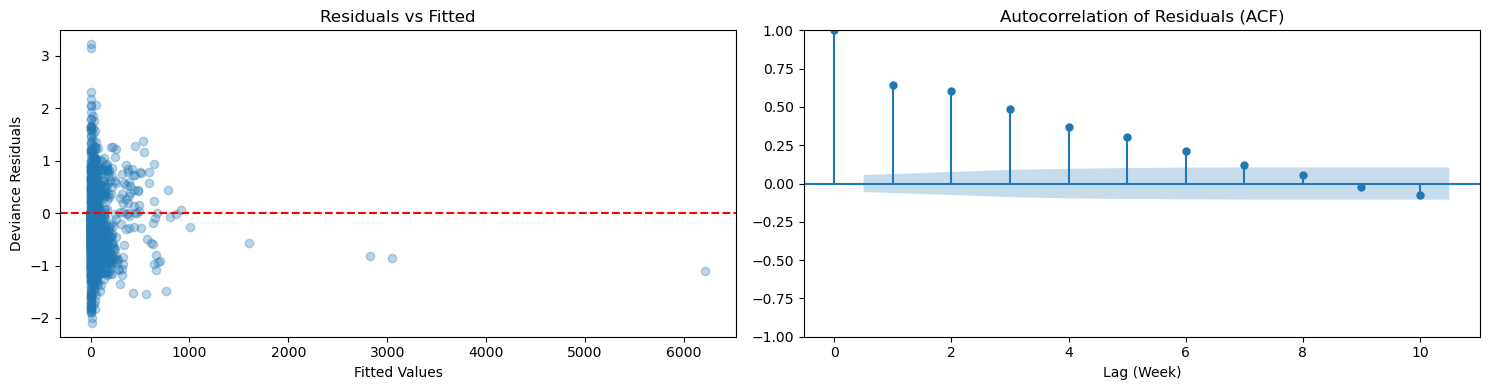

DPT RR range: 0.319 to 10.548


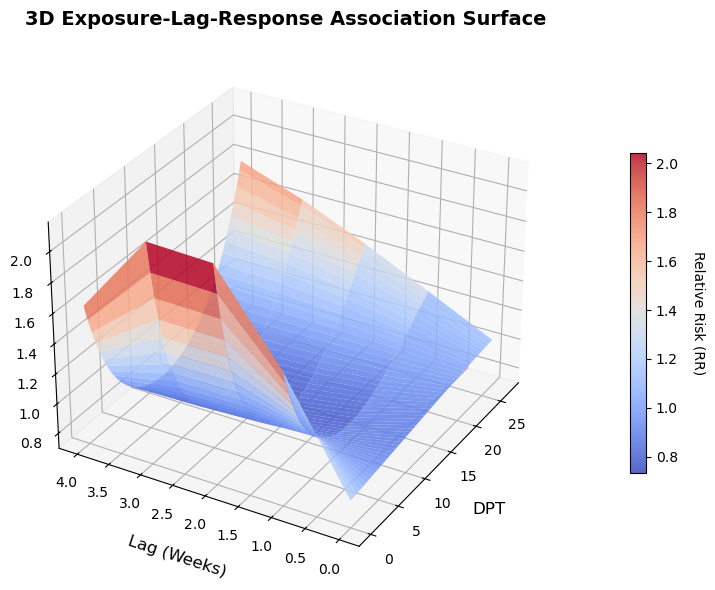

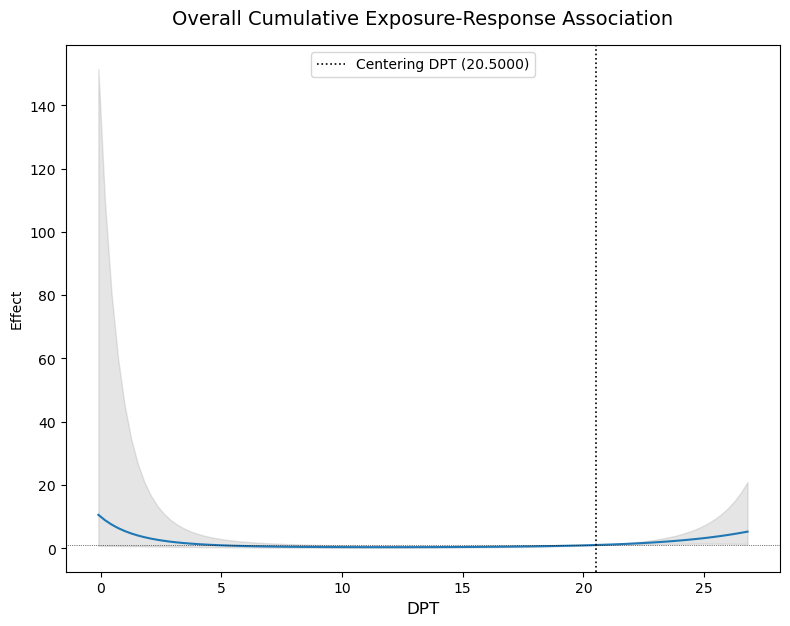

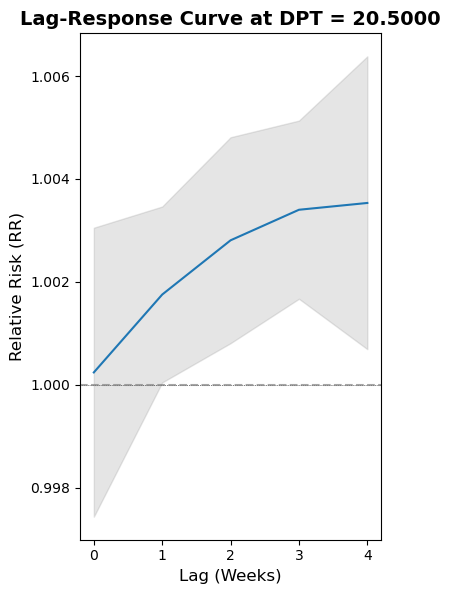


=============== Final PyMC Zero-Inflated Negative Binomial ===============
Sampling separated ZINB model …


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 202 seconds.


Output()

===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.994,0.004,0.987,0.998,2521.825,1780.477,1.002,0.000,0.000
psi[1],0.994,0.004,0.987,0.998,2521.825,1780.477,1.002,0.000,0.000
psi[2],0.994,0.004,0.987,0.998,2521.825,1780.477,1.002,0.000,0.000
psi[3],0.994,0.004,0.987,0.998,2521.825,1780.477,1.002,0.000,0.000
psi[4],0.994,0.004,0.987,0.998,2521.825,1780.477,1.002,0.000,0.000
...,...,...,...,...,...,...,...,...,...
beta[Week_s12],-0.819,0.200,-1.133,-0.500,3479.917,3763.483,1.001,0.003,0.002
gamma[intercept_psi],3.964,0.645,3.007,5.050,5467.669,3473.563,1.001,0.009,0.010
gamma[school_flag],1.318,0.753,0.198,2.532,3756.485,2846.436,1.001,0.013,0.015
gamma[pandemic_flag],-4.035,1.589,-5.573,-0.209,1342.592,611.468,1.004,0.060,0.069


DPT RR range: 0.556 to 41.156


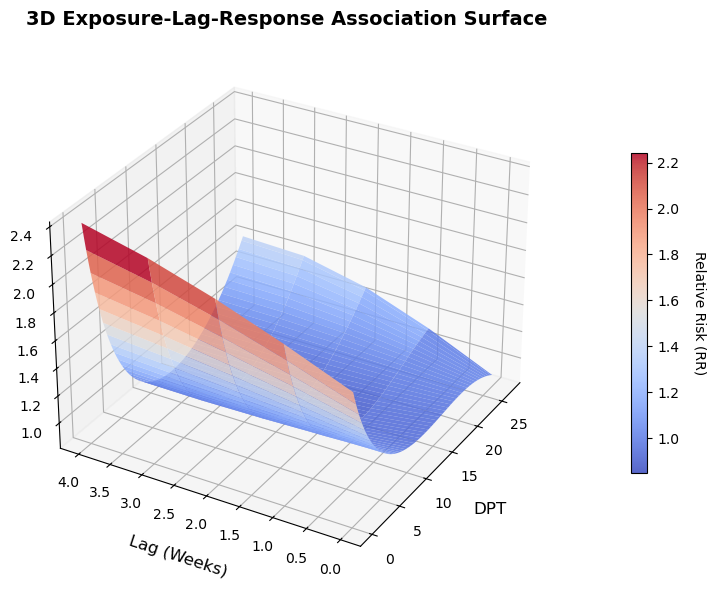

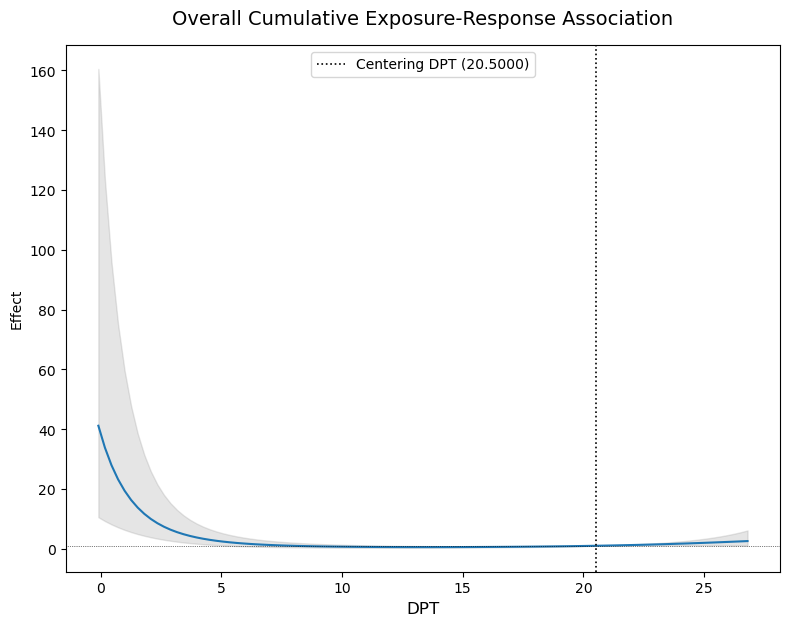

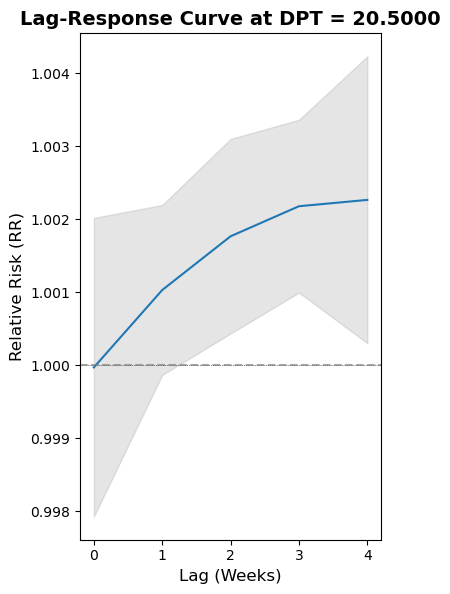

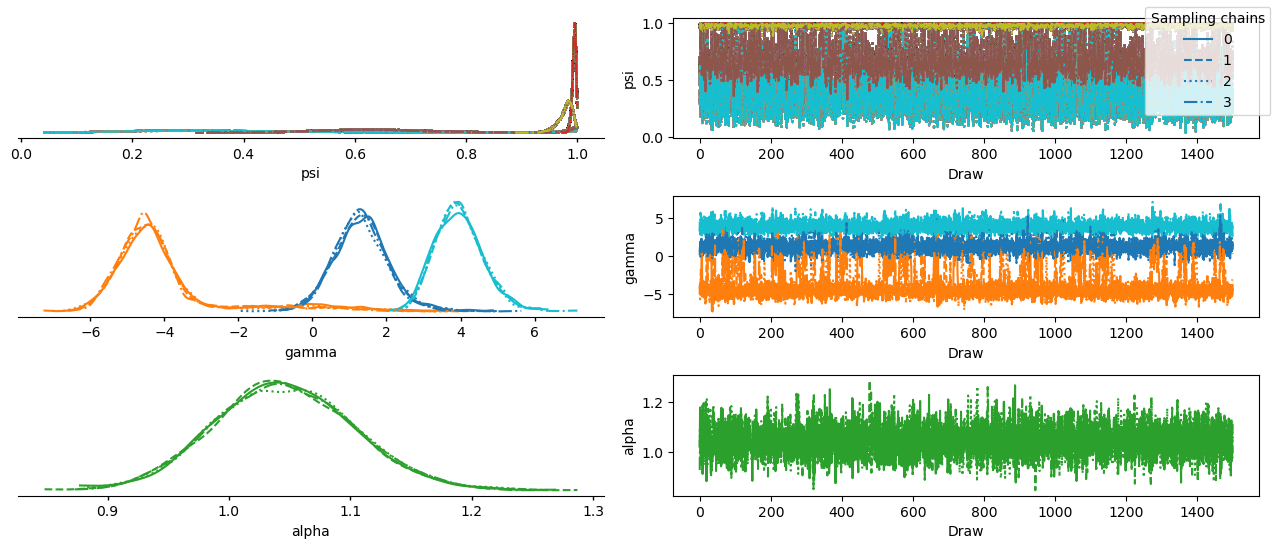

IN-SAMPLE metrics: not a forecast-performance estimate.


c:\Users\yanss\anaconda3\Lib\site-packages\arviz_stats\loo\loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,in_sample_value
n_observations,1249.000000
MAE_predictive_median,46.379103
RMSE_predictive_mean,130.837572
mean_prediction_minus_observed,-11.444680
observed_zero_fraction,0.375500
predicted_zero_fraction,0.335620
zero_event_Brier_score,0.071345
coverage_80,0.903923
coverage_95,0.982386
mean_interval_width_80,130.042594


,value
divergences,0.000000
max_r_hat,1.003506
min_bulk_ESS,1342.592375
min_tail_ESS,611.467674


,Pearson_residual_ACF
1,0.674999
2,0.600461
3,0.471295
4,0.339618
5,0.250171
6,0.169683
7,0.096365
8,0.037975
9,-0.010209
10,-0.063386


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1249 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -3960.60    93.09
p_loo       65.46        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1246   99.8%
   (0.70, 1]   (bad)         3    0.2%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept_mu],5957,4044,1.00,0.0098,0.011
beta[DPT_basis_0],4806,3883,1.00,0.0091,0.0083
beta[DPT_basis_1],6520,4875,1.00,0.0096,0.0092
beta[DPT_basis_2],5850,4596,1.00,0.0079,0.0076
beta[DPT_basis_3],5039,4338,1.00,0.0052,0.0049
beta[DPT_basis_4],6884,4636,1.00,0.0069,0.0077
beta[DPT_basis_5],6208,4798,1.00,0.0044,0.0043
beta[DPT_basis_6],5352,3968,1.00,0.0055,0.0054
beta[DPT_basis_7],6074,4588,1.00,0.0072,0.0066
beta[DPT_basis_8],4978,4371,1.00,0.0056,0.0049



--- Residual diagnostics (ZINB) ---


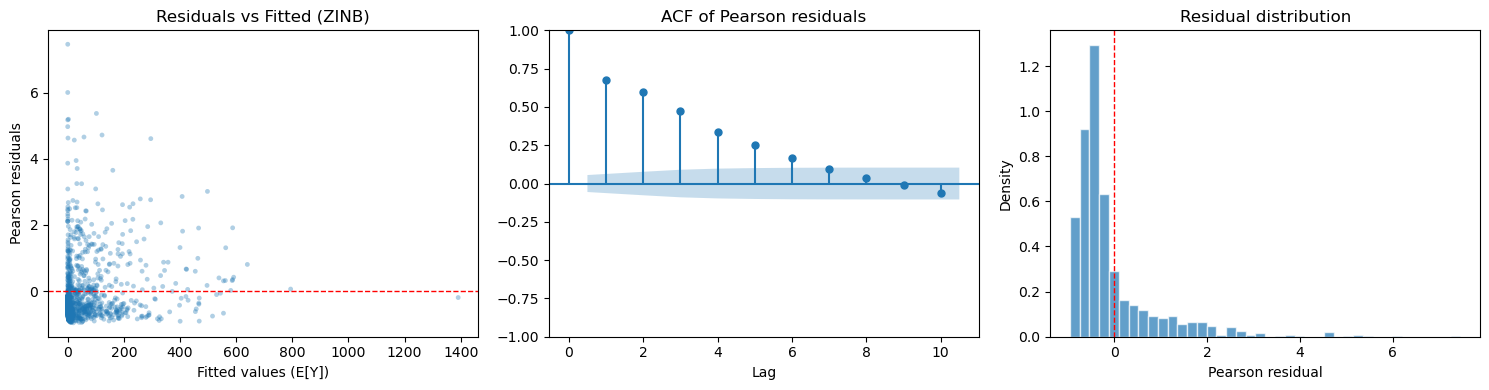

Pearson residual mean   : -0.0713
Pearson residual std    : 0.9403
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.948


**============================== WS (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9686.85
BIC for (2, 3, 2, 4): 9704.34
BIC for (2, 3, 3, 3): 9704.34
BIC for (2, 3, 3, 4): 9704.34
BIC for (2, 4, 2, 3): 9700.15
BIC for (2, 4, 2, 4): 9723.79
BIC for (2, 4, 3, 3): 9723.79
BIC for (2, 4, 3, 4): 9723.79
BIC for (3, 3, 2, 3): 9676.72
BIC for (3, 3, 2, 4): 9694.27
BIC for (3, 3, 3, 3): 9694.27
BIC for (3, 3, 3, 4): 9694.27
BIC for (3, 4, 2, 3): 9688.17
BIC for (3, 4, 2, 4): 9714.19
BIC for (3, 4, 3, 3): 9714.19
BIC for (3, 4, 3, 4): 9714.19
Best CrossBasis setting: (3, 3, 2, 3) (BIC = 9676.72)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (25, 4, 8): BIC=8197.8715 | sum(EDF)=45.3930
Degrees of freedom (25, 4, 10): BIC=8201.9358 | sum(EDF)=46.8868
Degrees of freedom (25, 4, 12): BIC=8208.0651 | sum(EDF)=48.1656
Degrees of freedom (25, 4, 14): BIC=8213.9458 | sum(EDF)=49.0013
Degrees of freedom (25, 5, 8): BIC=8197.8715 | sum(EDF)=45.3930
Degrees of freedom (25, 5, 10): BIC=

,alpha,AIC,BIC,GCV,EDF
KFold,"(5.011872336272722, 1.0, 630.957344480193)",7679.197787,7965.092377,1.095586,55.728869



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   1.5: Pearson ratio = 5.1361 | BIC = 8096.4446
Dispersion   2.0: Pearson ratio = 3.3323 | BIC = 8230.2353
Dispersion   3.0: Pearson ratio = 1.5534 | BIC = 8488.9202
Dispersion   5.0: Pearson ratio = 0.5652 | BIC = 8906.1581

Best dispersion parameter: 5.0 (Pearson ratio = 0.5652)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                           -16.3471   1.82e+06     -9e-06      1.000   -3.56e+06    3.56e+06
WS_basis_0                            0.9334      1.504      0.621      0.535      -2.014       3.881
WS_basis_1                            1.8756      2.627      0.714      0.475      -3.273       7.025
WS_basis_2                            1.4531      1.490      

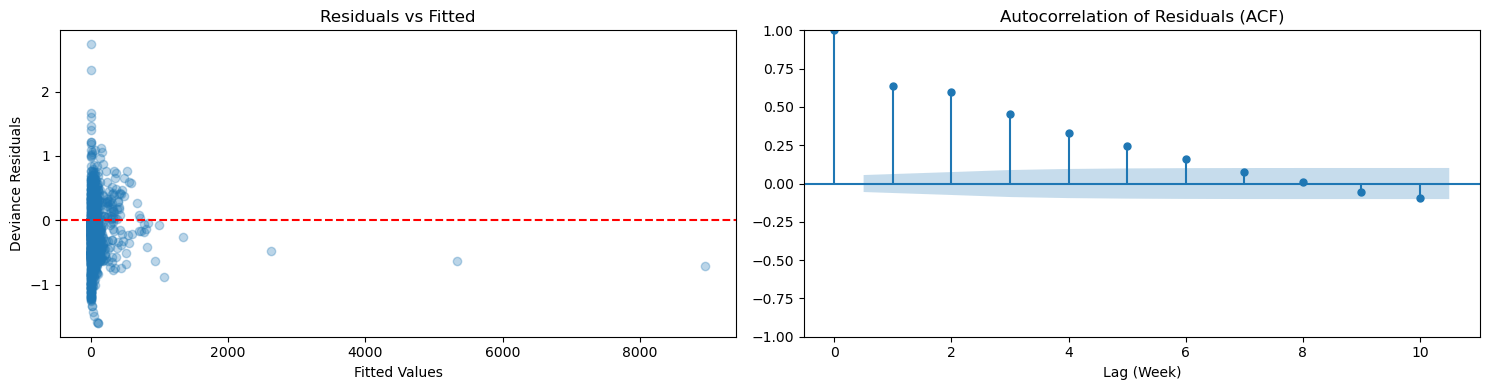

WS RR range: 0.061 to 10.694


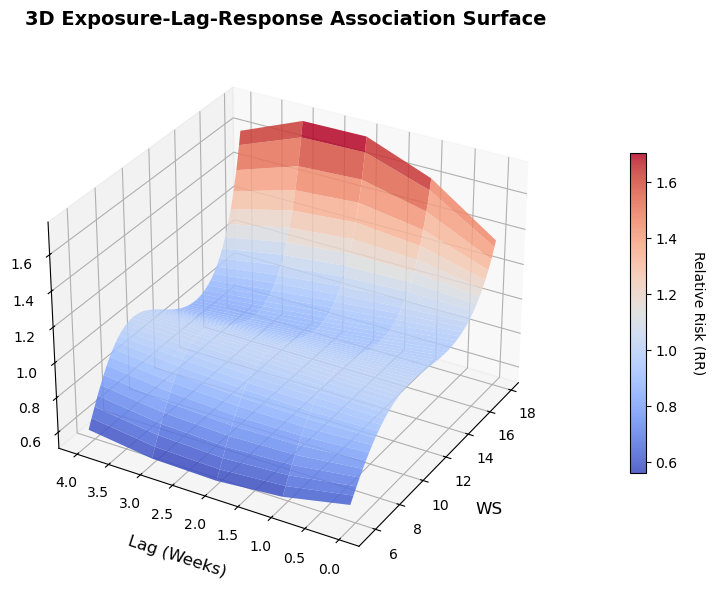

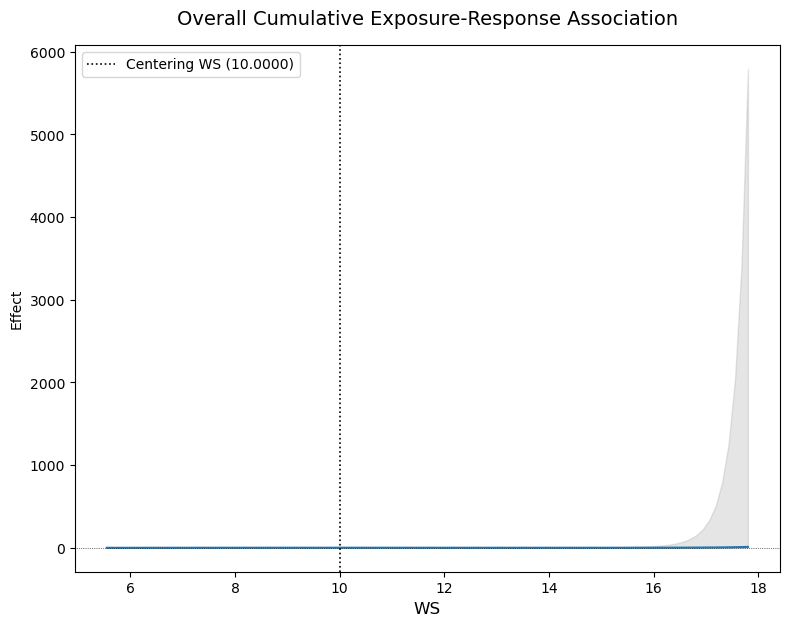

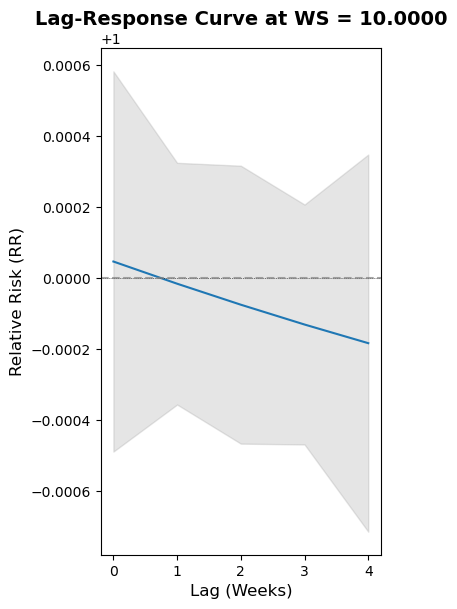


=============== Final PyMC Zero-Inflated Negative Binomial ===============
Sampling separated ZINB model …


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 201 seconds.


Output()

===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.992,0.004,0.985,0.997,6206.759,4950.161,1.000,0.000,0.000
psi[1],0.992,0.004,0.985,0.997,6206.759,4950.161,1.000,0.000,0.000
psi[2],0.992,0.004,0.985,0.997,6206.759,4950.161,1.000,0.000,0.000
psi[3],0.992,0.004,0.985,0.997,6206.759,4950.161,1.000,0.000,0.000
psi[4],0.992,0.004,0.985,0.997,6206.759,4950.161,1.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...
beta[Week_s12],-1.362,0.163,-1.617,-1.102,6201.906,4967.257,1.002,0.002,0.002
gamma[intercept_psi],3.799,0.581,2.900,4.783,4823.340,4068.764,1.000,0.008,0.007
gamma[school_flag],1.189,0.607,0.212,2.155,5349.586,4305.578,1.000,0.008,0.008
gamma[pandemic_flag],-4.902,0.577,-5.849,-4.002,5382.039,4385.467,1.001,0.008,0.008


WS RR range: 0.335 to 1.246


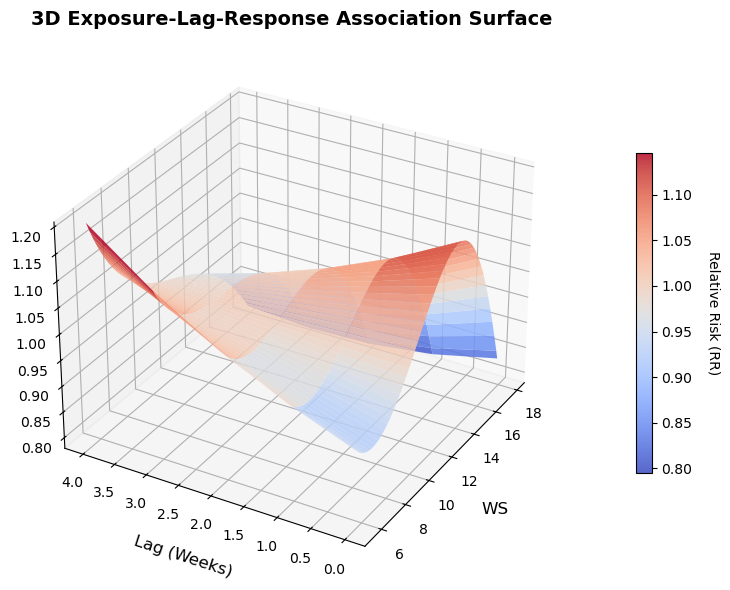

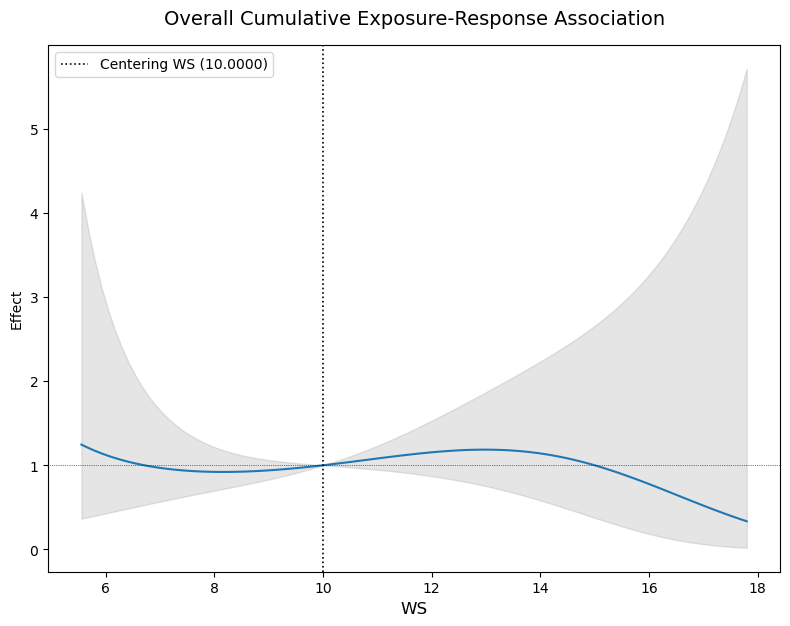

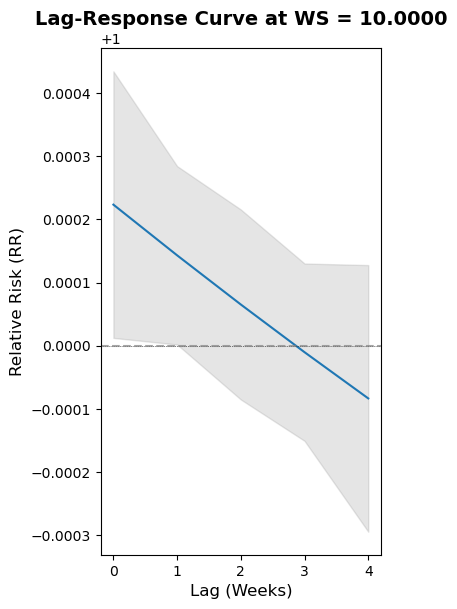

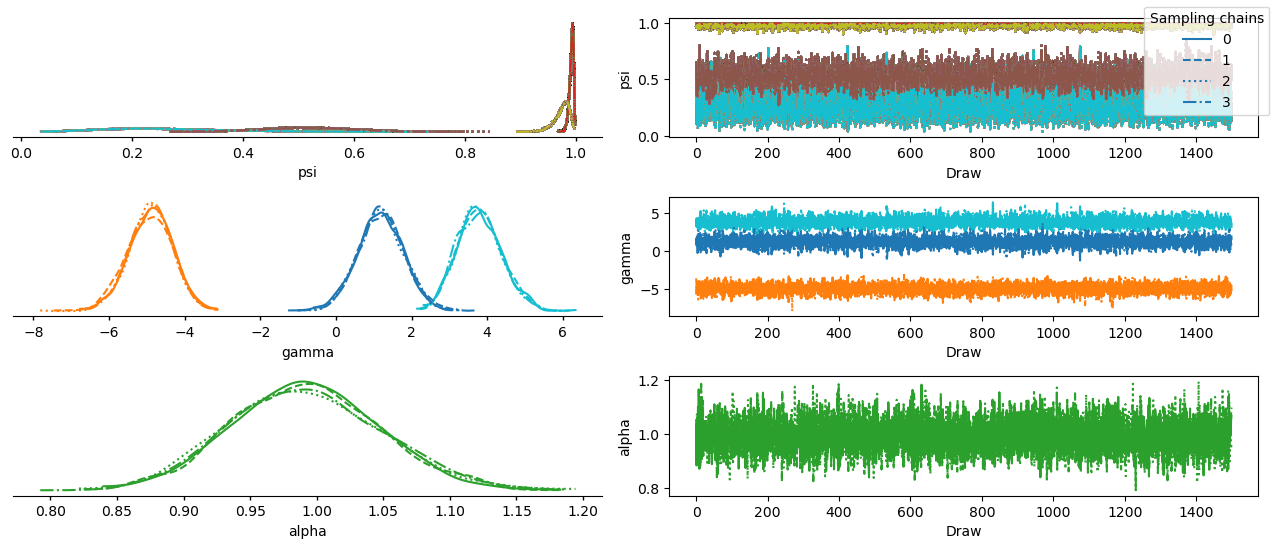

IN-SAMPLE metrics: not a forecast-performance estimate.


c:\Users\yanss\anaconda3\Lib\site-packages\arviz_stats\loo\loo_helper.py:1169: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,in_sample_value
n_observations,1249.000000
MAE_predictive_median,46.496797
RMSE_predictive_mean,133.509220
mean_prediction_minus_observed,-8.595347
observed_zero_fraction,0.375500
predicted_zero_fraction,0.334822
zero_event_Brier_score,0.080590
coverage_80,0.904724
coverage_95,0.979984
mean_interval_width_80,139.932586


,value
divergences,0.000000
max_r_hat,1.002460
min_bulk_ESS,3069.869757
min_tail_ESS,3513.331519


,Pearson_residual_ACF
1,0.699919
2,0.630912
3,0.483602
4,0.366490
5,0.263930
6,0.179767
7,0.102805
8,0.033362
9,-0.018367
10,-0.069730


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1249 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -3994.93    93.27
p_loo       58.57        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1247   99.8%
   (0.70, 1]   (bad)         2    0.2%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept_mu],4254,4024,1.00,0.011,0.0091
beta[WS_basis_0],5101,4644,1.00,0.0073,0.0057
beta[WS_basis_1],5966,4511,1.00,0.009,0.0087
beta[WS_basis_2],4945,4778,1.00,0.0074,0.006
beta[WS_basis_3],4845,4861,1.00,0.0053,0.004
beta[WS_basis_4],5565,5006,1.00,0.0071,0.006
beta[WS_basis_5],3773,4373,1.00,0.0062,0.0044
beta[WS_basis_6],4415,4305,1.00,0.0081,0.0062
beta[WS_basis_7],5296,4885,1.00,0.0098,0.0084
beta[WS_basis_8],3559,3983,1.00,0.0095,0.0066



--- Residual diagnostics (ZINB) ---


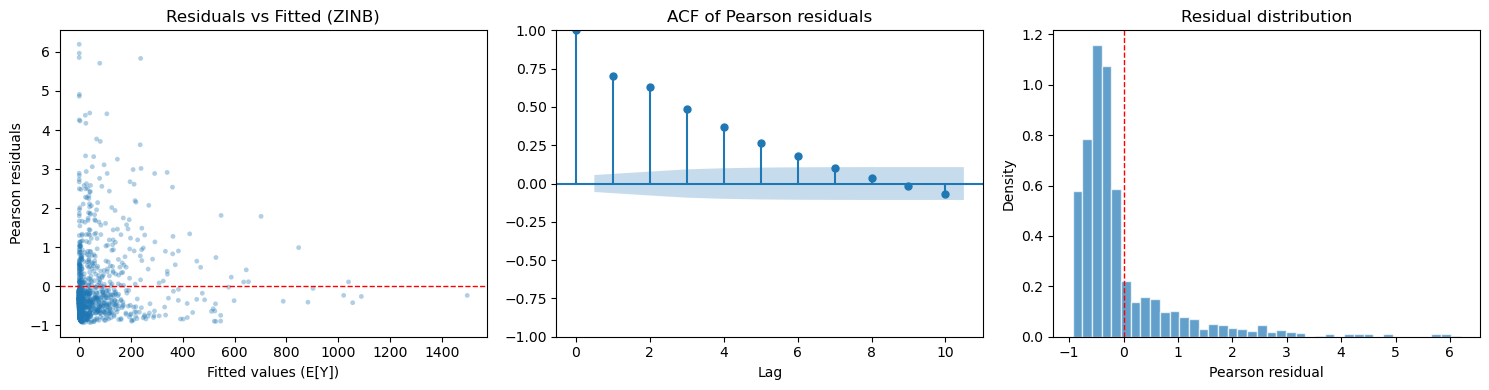

Pearson residual mean   : -0.0676
Pearson residual std    : 0.9441
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.925


**============================== UV (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9645.17
BIC for (2, 3, 2, 4): 9667.13
BIC for (2, 3, 3, 3): 9667.13
BIC for (2, 3, 3, 4): 9667.13
BIC for (2, 4, 2, 3): 9637.98
BIC for (2, 4, 2, 4): 9669.41
BIC for (2, 4, 3, 3): 9669.41
BIC for (2, 4, 3, 4): 9669.41
BIC for (3, 3, 2, 3): 9630.43
BIC for (3, 3, 2, 4): 9652.96
BIC for (3, 3, 3, 3): 9652.96
BIC for (3, 3, 3, 4): 9652.96
BIC for (3, 4, 2, 3): 9612.31
BIC for (3, 4, 2, 4): 9645.21
BIC for (3, 4, 3, 3): 9645.21
BIC for (3, 4, 3, 4): 9645.21
Best CrossBasis setting: (3, 4, 2, 3) (BIC = 9612.31)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (25, 4, 8): BIC=8168.6428 | sum(EDF)=48.0712
Degrees of freedom (25, 4, 10): BIC=8168.6505 | sum(EDF)=49.5998
Degrees of freedom (25, 4, 12): BIC=8170.6038 | sum(EDF)=50.9650
Degrees of freedom (25, 4, 14): BIC=8175.2169 | sum(EDF)=51.8134
Degrees of freedom (25, 5, 8): BIC=8168.6428 | sum(EDF)=48.0712
Degrees of freedom (25, 5, 10): BIC=

,alpha,AIC,BIC,GCV,EDF
KFold,"(25.118864315095795, 1.0, 1.0)",7683.838056,8036.920472,1.120037,68.82566



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   1.5: Pearson ratio = 1.3347 | BIC = 8158.6080
Dispersion   2.0: Pearson ratio = 0.7344 | BIC = 8295.2796
Dispersion   3.0: Pearson ratio = 0.4715 | BIC = 8554.1102
Dispersion   5.0: Pearson ratio = 0.3138 | BIC = 8974.7721

Best dispersion parameter: 2.0 (Pearson ratio = 0.7344)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -7.2262      3.189     -2.266      0.023     -13.477      -0.976
UV_basis_0                           -0.0699      0.655     -0.107      0.915      -1.354       1.214
UV_basis_1                           -0.4238      1.146     -0.370      0.711      -2.669       1.821
UV_basis_2                           -0.1208      0.666     -

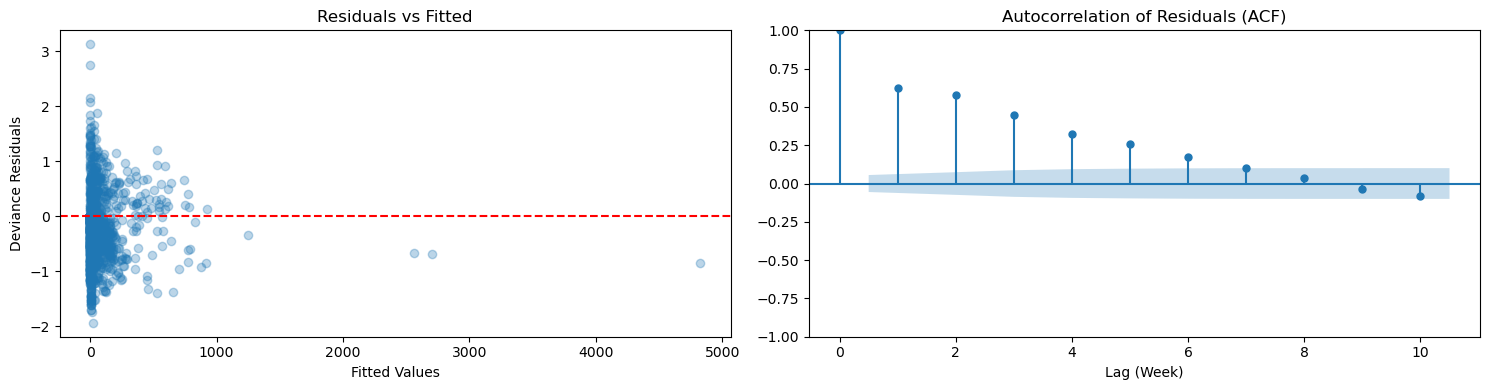

UV RR range: 0.598 to 737.504


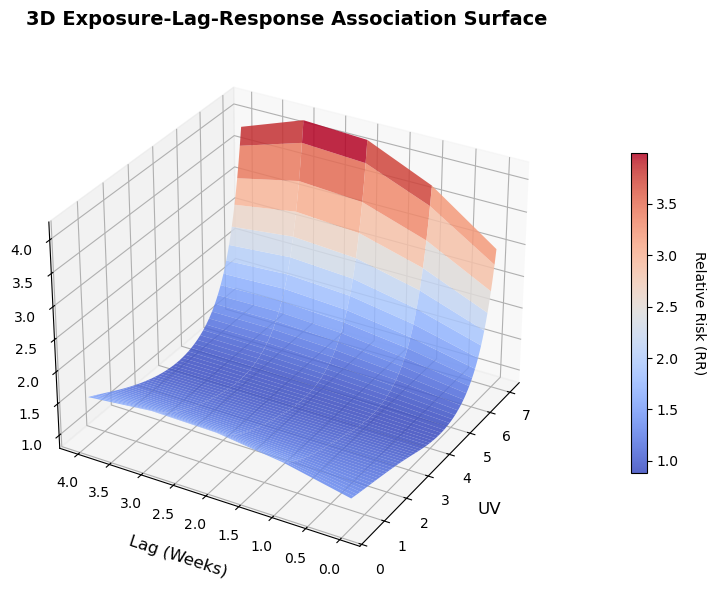

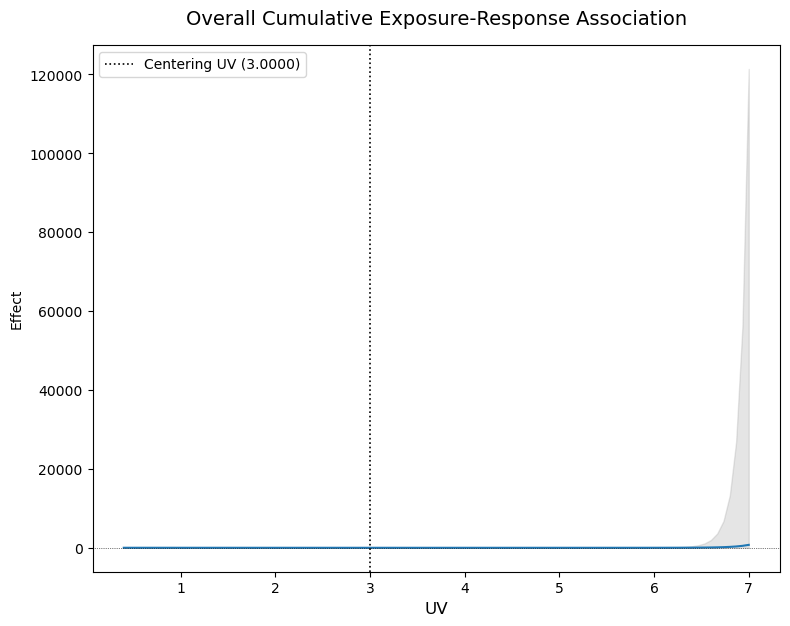

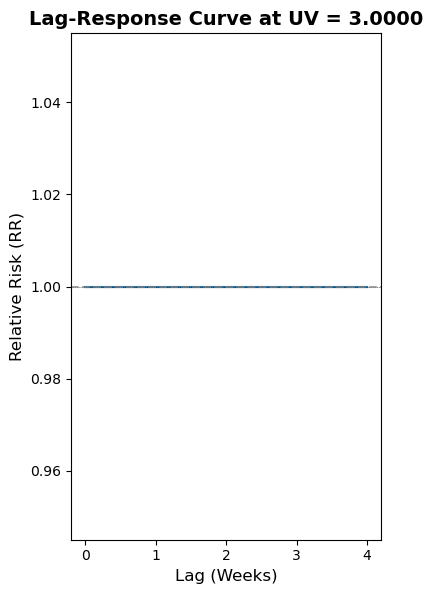


=============== Final PyMC Zero-Inflated Negative Binomial ===============
Sampling separated ZINB model …


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 184 seconds.


Output()

===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.993,0.004,0.987,0.998,2939.939,2067.395,1.001,0.000,0.000
psi[1],0.993,0.004,0.987,0.998,2939.939,2067.395,1.001,0.000,0.000
psi[2],0.993,0.004,0.987,0.998,2939.939,2067.395,1.001,0.000,0.000
psi[3],0.993,0.004,0.987,0.998,2939.939,2067.395,1.001,0.000,0.000
psi[4],0.993,0.004,0.987,0.998,2939.939,2067.395,1.001,0.000,0.000
...,...,...,...,...,...,...,...,...,...
beta[Week_s12],-1.375,0.167,-1.643,-1.110,4649.236,4595.759,1.000,0.002,0.002
gamma[intercept_psi],3.908,0.640,2.958,4.991,5222.331,3473.586,1.000,0.009,0.009
gamma[school_flag],1.276,0.733,0.155,2.385,4074.702,2774.008,1.002,0.012,0.017
gamma[pandemic_flag],-4.301,1.282,-5.609,-2.102,1175.588,614.223,1.002,0.056,0.097


UV RR range: 0.840 to 21.337


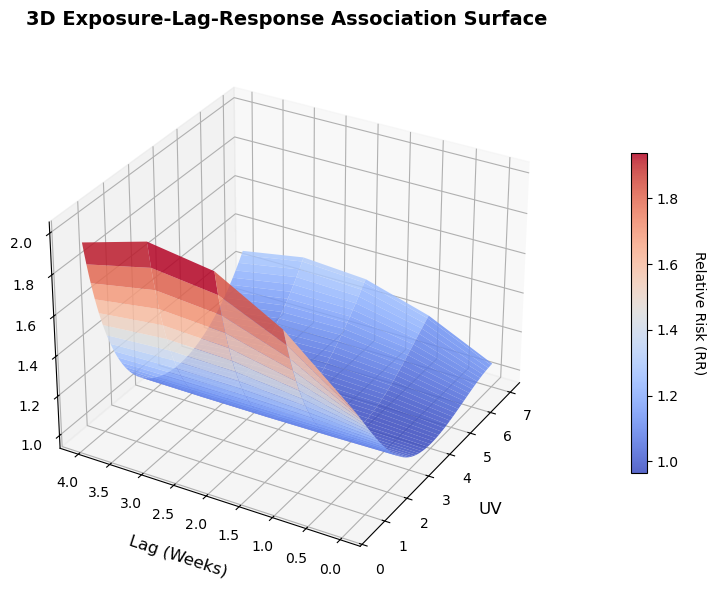

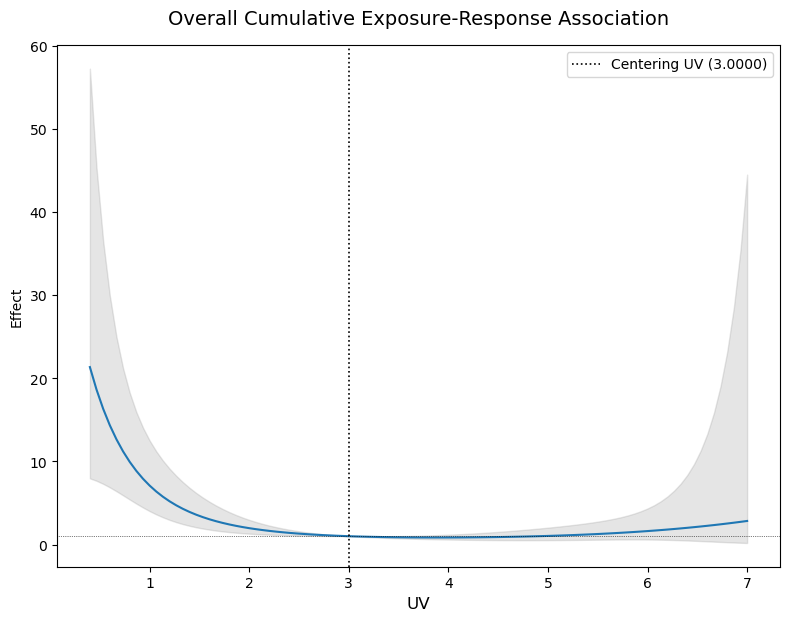

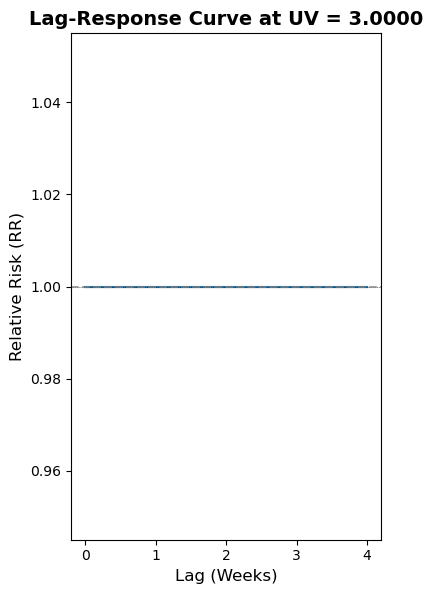

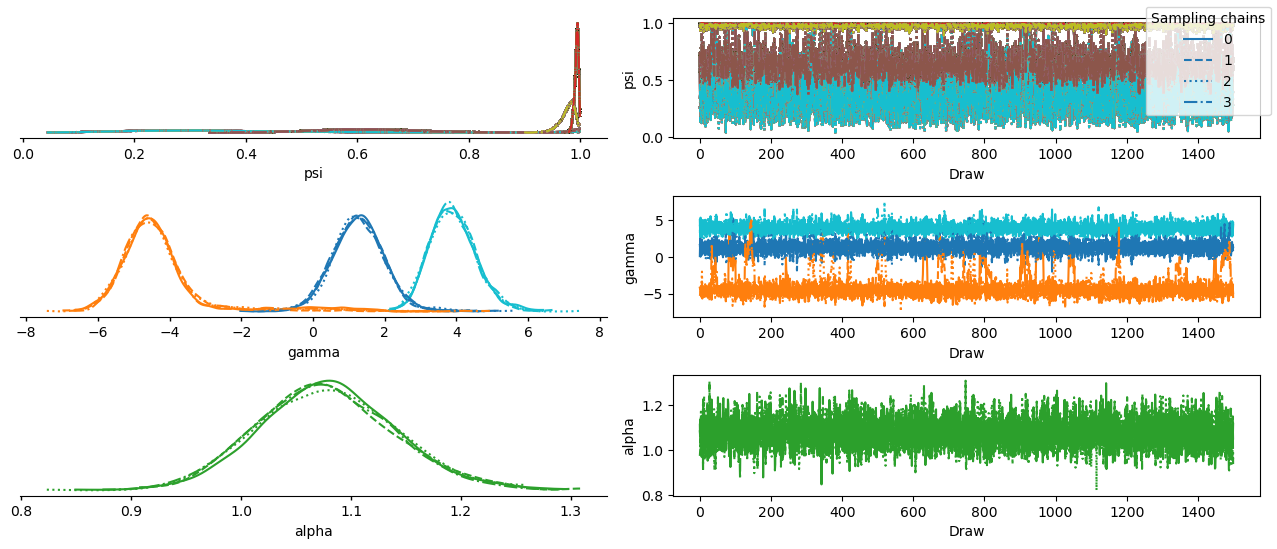

IN-SAMPLE metrics: not a forecast-performance estimate.


,in_sample_value
n_observations,1249.000000
MAE_predictive_median,45.758207
RMSE_predictive_mean,124.637506
mean_prediction_minus_observed,-11.025588
observed_zero_fraction,0.375500
predicted_zero_fraction,0.333253
zero_event_Brier_score,0.075295
coverage_80,0.907126
coverage_95,0.982386
mean_interval_width_80,130.997758


,value
divergences,0.000000
max_r_hat,1.002386
min_bulk_ESS,1175.587583
min_tail_ESS,614.222970


,Pearson_residual_ACF
1,0.666241
2,0.569233
3,0.440316
4,0.308394
5,0.222979
6,0.144847
7,0.083272
8,0.019534
9,-0.031154
10,-0.083450


Computed; inspect Pareto-k diagnostics. This is not leave-future-out validation.
Computed from 6000 posterior samples and 1249 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -3954.90    92.45
p_loo       66.57        -
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)     1249  100.0%
   (0.70, 1]   (bad)         0    0.0%
    (1, Inf)   (very bad)    0    0.0%



,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta[intercept_mu],4264,4404,1.00,0.01,0.0078
beta[UV_basis_0],3984,4361,1.00,0.0054,0.004
beta[UV_basis_1],4783,4782,1.00,0.0071,0.0057
beta[UV_basis_2],3812,4104,1.00,0.0056,0.004
beta[UV_basis_3],4436,4455,1.00,0.0043,0.0032
beta[UV_basis_4],5953,4900,1.00,0.0056,0.0049
beta[UV_basis_5],4515,4305,1.00,0.0042,0.0031
beta[UV_basis_6],3802,4393,1.00,0.0073,0.0054
beta[UV_basis_7],4704,4697,1.00,0.009,0.007
beta[UV_basis_8],3495,3376,1.00,0.0078,0.0054



--- Residual diagnostics (ZINB) ---


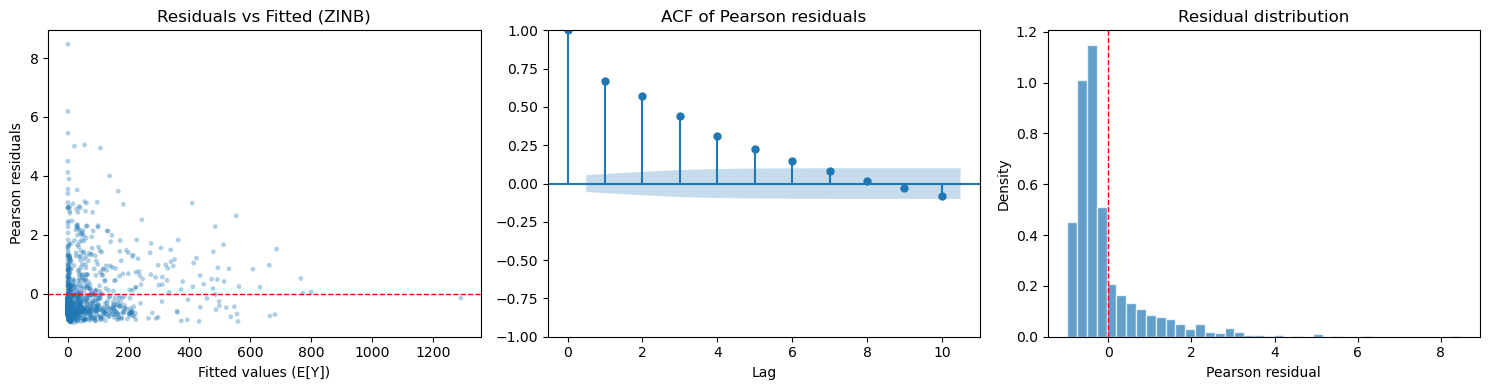

Pearson residual mean   : -0.0722
Pearson residual std    : 0.9417
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.943


In [481]:
# Remaining meterological variables
tar_var = "H1"
for exp in mete_col[1:]:
    exp_col_list = [exp]

    display(Markdown(f"**{'='*30} {exp} (ZINB) {'='*30}**"))

    idata, pred, model_data, cb_list, colnames, nb_result, resid, report = DLNM_ZINB(
        df, max_lag=4,
        tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list,
        bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
        cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=[],
        # PyMC controls – reduce draws/tune for a quick test
        draws=1500, tune=1500, target_accept=0.95, chains=4, cores=4, psi_prior="logistic", prior_sigma=1.0
    )


---